# Geoneutrinos (and reactor neutrinos) do not visibly decay

Every figure of the paper, redrawn from the files in `data/` with the paper's own plotting code. Run the cells in order; each figure is written to `figures/` as a PDF.

Each figure reads one file, `data/<figure>.json`: the results of the functions that the paper's code calls to draw it, each with the arguments it was called with (`plotting/data.py` reads them). The limits themselves are in `data/limits.json`.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator, MultipleLocator

sys.path.insert(0, "..")
from plotting import data, helpers, style

style.use()
#: Where the figures go.
FIGURES = os.path.join("..", "figures")
os.makedirs(FIGURES, exist_ok=True)

#: The lifetime the single-lifetime figures illustrate, log10(tau_1/m_1 [s/eV]).
TAU = -9.0
#: The lifetimes the neutrino spectrum compares.
TAUS = (-8.0, -9.0)
#: The site of the neutrino spectrum and of the signal by distance.
SITE = "borexino"
#: One colour and one dash pattern per lifetime, the same in every figure.
COLORS = {None: "k", -8.0: "#0b6fa4", -9.0: "#c1272d", -10.0: "#e6a817"}
DASHES = {None: "-", -8.0: "--", -9.0: "-.", -10.0: ":"}
#: The reservoirs' colours, darkest nearest the detector, adjacent ones at least 9.8 apart (deltaE x 100,
#: OKLab).
RESERVOIR_COLORS = {"crust_local": "#8c510a", "crust_roc": "#c49a4c", "lithospheric_mantle": "#e3c88a",
                    "mantle": "#f6e8c3"}
#: The chains' colours, the same in every figure (ColorBrewer PiYG): lines, and the fills of totals.
#: None of them means something else in the paper, and the two stay distinct under every
#: colour-vision deficiency (deltaE x 100 >= 11.5 in OKLab, lines and fills).
CHAIN_LINE = {"U238": "#c51b7d", "Th232": "#4d9221"}
CHAIN_FILL = {"U238": "#f1b6da", "Th232": "#b8e186"}
#: The components' colours in the comparison with the published spectra.
COMPONENT_COLORS = {"geo": "#c1272d", "reactor": "#0b6fa4", "alpha_n": "#8a6d3b", "li9": "#2e7d32",
                    "accidental": "#6a51a3", "other": "#6a6a6a"}
#: Each analysis as the panels name it, with its year.
ANALYSES = {"borexino": "Borexino (2020)", "kamland": "KamLAND (2022)", "snoplus": "SNO+ (2026)",
            "juno": "JUNO (2026)"}
#: The decay channel the figures illustrate.
CHANNEL = r"$\nu_1 \to \nu_3$ (IO)"
#: The prompt-energy range every panel of the spectra shares, MeV: JUNO's bins to 9.4 MeV.
X_RANGE = (0.7, 9.4)
#: The top of each experiment's panel, in events per MeV, and its tick marks.
Y_TOP = {"borexino": 85, "kamland": 1000, "snoplus": 100, "juno": 800}
Y_TICKS = {"borexino": (0, 20, 40, 60, 80), "kamland": (0, 200, 400, 600, 800), "snoplus": (0, 20, 40, 60, 80),
           "juno": (0, 200, 400, 600)}
#: The y-axis label of the spectra: every bin's count over its width, since the widths differ.
EVENTS_LABEL = r"Detected events [MeV$^{-1}$]"
#: The size of the legends that carry a figure's key.
LEGEND_SIZE = 20
#: The size of axis labels, which the panel labels match.
LABEL_SIZE = plt.rcParams["axes.labelsize"]


def tau_label(log10_tau):
    """A lifetime as the figures write it."""
    return rf"$\tau_1/m_1 = 10^{{{int(round(log10_tau))}}}$~s~eV$^{{-1}}$"


def tag(ax, text, x=0.025, y=0.955, ha="left", va="top", size=None):
    """A rounded-box label in a corner of a panel, as large as the axis labels."""
    ax.text(x, y, text, transform=ax.transAxes, ha=ha, va=va, fontsize=size or LABEL_SIZE, zorder=10,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="k", lw=0.8))


def minor_ticks(ax, x=True, y=True):
    """Minor tick marks, four per major interval."""
    if x:
        ax.xaxis.set_minor_locator(AutoMinorLocator(4))
    if y:
        ax.yaxis.set_minor_locator(AutoMinorLocator(4))


def energy_ticks(ax):
    """A labeled tick every MeV on the spectra's common prompt-energy axis, and minor ones between."""
    ax.xaxis.set_major_locator(MultipleLocator(1.0))
    ax.xaxis.set_minor_locator(MultipleLocator(0.25))


def stack_ylabel(axes_stack, text, on=None):
    """One y-axis label for a stack of panels, next to a panel's tick labels and centred on the stack.

    Matplotlib places an axis label beside its tick labels, so the label goes on one panel
    (``on``, the stack's second by default) and is moved, along the axis only, to the middle
    of the stack.
    """
    on = on if on is not None else axes_stack[1]
    top, bottom = axes_stack[0].get_position().y1, axes_stack[-1].get_position().y0
    pos = on.get_position()
    on.set_ylabel(text)
    on.yaxis.label.set_y((0.5 * (top + bottom) - pos.y0) / pos.height)


def save(fig, name):
    """Write a figure as a PDF into figures/."""
    path = os.path.join(FIGURES, name + ".pdf")
    # No creation date in the file, so that drawing a figure again gives the same bytes.
    fig.savefig(path, bbox_inches="tight", metadata={"CreationDate": None})
    print("wrote", os.path.relpath(path, ".."))

## Figure 1

Lower limits on the neutrino lifetime-to-mass ratio, $\tau_i/m_i$, from visible decay. Our limits, from the four experiments combined with the Earth's radiogenic power free, next to the bounds published by others.

Data: `data/money_plot.json`.

wrote figures/money_plot.pdf


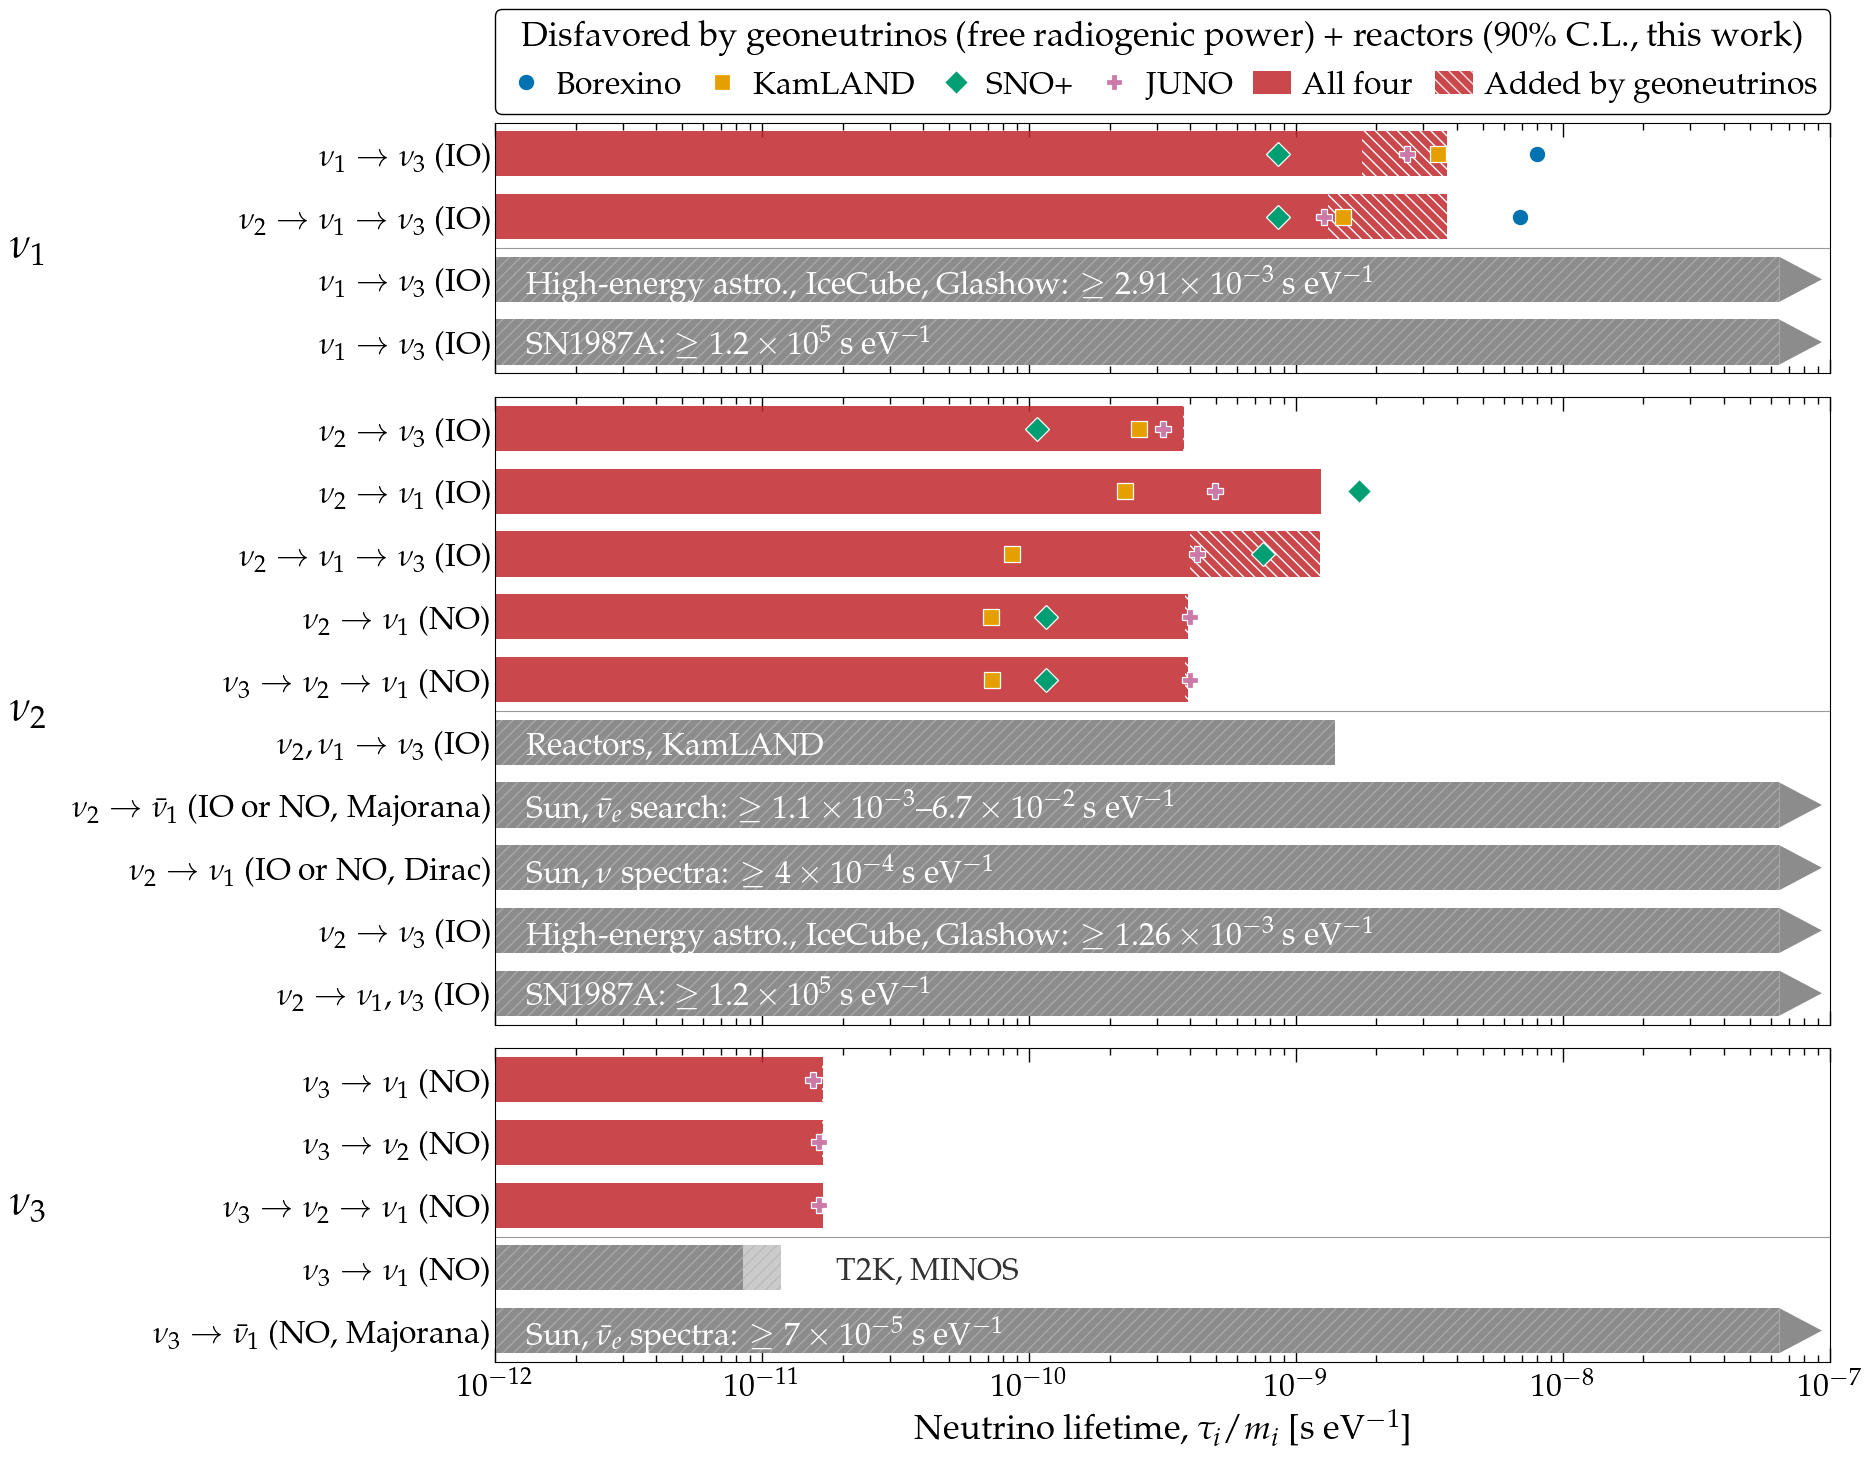

In [2]:
figdata = data.use("money_plot")
from plotting import money as plot_money

fig = plot_money.figure()
save(fig, "money_plot")
plt.show()

## Figure 2

Survival probability of geoneutrinos against the distance they travel, without decay and with $\nu_1 \to \nu_3$ in the inverted mass ordering.

Data: `data/survival_vs_distance.json`.

wrote figures/survival_vs_distance.pdf


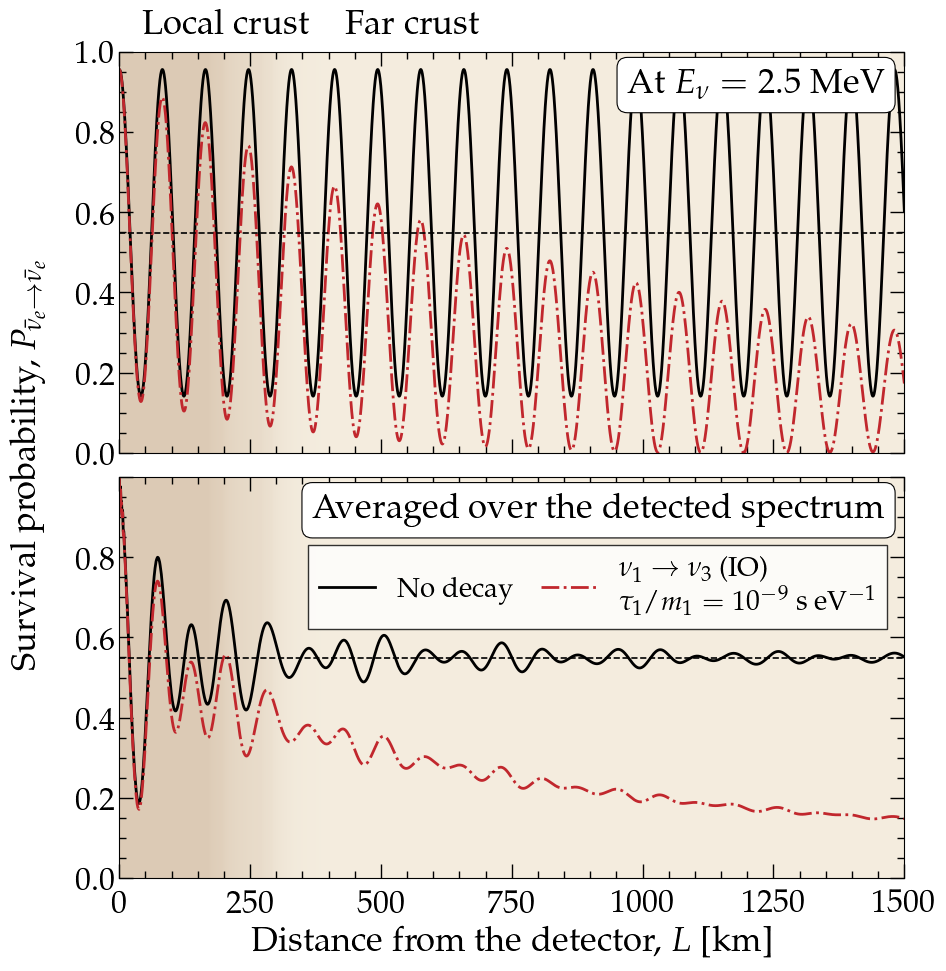

at    350 km: no decay 0.557, with decay 0.373
at   1500 km: no decay 0.551, with decay 0.148
fully averaged: 0.549
Borexino's local box: every circle inside out to 172 km, none beyond 404 km


In [3]:
figdata = data.use("survival_vs_distance")
from matplotlib.colors import to_rgb

box_coverage = figdata.box_coverage
LOCAL_BOXES = helpers.LOCAL_BOXES; site_coordinates = figdata.site_coordinates

sv = figdata.survival_vs_distance(TAU)
L, full = sv["distance"], sv["fully_averaged"]

#: The share of each circle around Borexino inside its local box, every kilometre.
RINGS = np.arange(0.0, L[-1] + 1.0, 1.0)
inside = box_coverage(site_coordinates(SITE) + LOCAL_BOXES[SITE], RINGS + 0.5)
inner, outer = RINGS[np.argmax(inside < 1.0)], RINGS[np.argmax(inside <= 0.0)]


def tint(color, alpha):
    """A colour as it shows at an opacity over white."""
    return 1.0 - alpha * (1.0 - np.array(to_rgb(color)))


# Each kilometre takes the local crust's tint by its share inside the box, the far crust's by the rest; the
# opacities keep the two apart.
shading = (inside[:, None] * tint(RESERVOIR_COLORS["crust_local"], 0.30)
           + (1.0 - inside[:, None]) * tint(RESERVOIR_COLORS["crust_roc"], 0.18))[None, :, :]

fig, axes = plt.subplots(2, 1, figsize=(10.0, 10.0), sharex=True, gridspec_kw={"hspace": 0.06})
for ax, view in zip(axes, ("single", "averaged")):
    ax.imshow(shading, extent=(RINGS[0], RINGS[-1] + 1.0, 0.0, 1.0), transform=ax.get_xaxis_transform(),
              aspect="auto", interpolation="nearest", zorder=0)
    ax.plot(L, sv[view][None], color=COLORS[None], ls=DASHES[None], lw=2.0, label="No decay")
    ax.plot(L, sv[view][TAU], color=COLORS[TAU], ls=DASHES[TAU], lw=2.0, label=CHANNEL + "\n" + tau_label(TAU))
    ax.axhline(full, color="k", ls="--", lw=1.2)
    ax.set_ylim(0.0, 1.0)
    ax.yaxis.set_major_locator(MultipleLocator(0.2))
    ax.yaxis.set_minor_locator(MultipleLocator(0.05))
tag(axes[0], r"At $E_\nu = 2.5$ MeV", x=0.975, y=0.96, ha="right")
tag(axes[1], "Averaged over the detected spectrum", x=0.975, y=0.96, ha="right")
above = dict(transform=axes[0].get_xaxis_transform(), va="bottom", fontsize=LABEL_SIZE)
axes[0].text(0.5 * outer, 1.02, "Local crust", ha="center", **above)
axes[0].text(560.0, 1.02, "Far crust", ha="center", **above)
axes[1].legend(loc="upper right", bbox_to_anchor=(0.995, 0.865), ncol=2, columnspacing=1.0, fontsize=LEGEND_SIZE,
               frameon=True, edgecolor="k", fancybox=False)
# The bottom panel's top tick label would collide with the top panel's bottom one.
axes[1].set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0], ["0.0", "0.2", "0.4", "0.6", "0.8", ""])
axes[1].set_xlim(0.0, L[-1])
axes[1].xaxis.set_major_locator(MultipleLocator(250))
axes[1].xaxis.set_minor_locator(MultipleLocator(50))
axes[1].set_xlabel(r"Distance from the detector, $L$ [km]")
# One y label, 4 pixels left of the widest tick labels and centred on the stack.
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
left = min(lab.get_window_extent(renderer).x0 for ax in axes for lab in ax.get_yticklabels() if lab.get_text())
x = fig.transFigure.inverted().transform((left - 4.0, 0.0))[0]
y = 0.5 * (axes[0].get_position().y1 + axes[1].get_position().y0)
fig.text(x, y, r"Survival probability, $P_{\bar\nu_e \to \bar\nu_e}$", rotation=90, ha="right", va="center",
         fontsize=LABEL_SIZE)
save(fig, "survival_vs_distance")
plt.show()

# The numbers the text quotes, from the averaged curves.
for at in (350.0, 1500.0):
    k = np.argmin(np.abs(L - at))
    print(f"at {L[k]:6.0f} km: no decay {sv['averaged'][None][k]:.3f}, with decay {sv['averaged'][TAU][k]:.3f}")
print(f"fully averaged: {full:.3f}")
print(f"Borexino's local box: every circle inside out to {inner:.0f} km, none beyond {outer:.0f} km")

## Figure 3

Flavor content of the three neutrino mass eigenstates allowed by NuFIT 6.1. Inverse beta decay sees only their electron flavor.

Data: `data/flavor_content.json`.

labels overlapping: none | labels touching a region: none


legend ink beyond the tick labels' ink: right +0.00 px, top +0.00 px
wrote figures/flavor_content.pdf


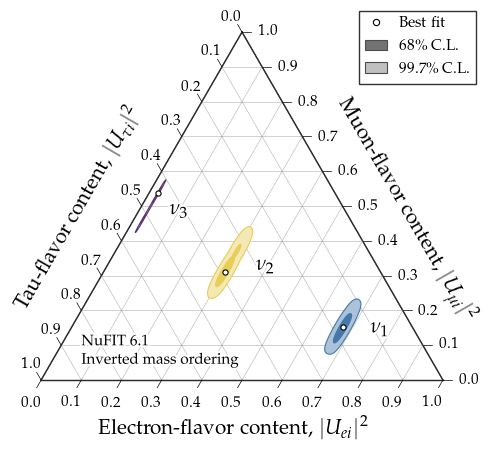

nu_1: |U_e1|^2 = 0.6756, 68% [0.6654, 0.6856], 99.7% [0.6520, 0.6976]
nu_2: |U_e2|^2 = 0.3018, 68% [0.2919, 0.3120], 99.7% [0.2798, 0.3254]
nu_3: |U_e3|^2 = 0.0226, 68% [0.0216, 0.0237], 99.7% [0.0205, 0.0249]


In [4]:
figdata = data.use("flavor_content")
import io
import re

import matplotlib.patheffects as path_effects
import ternary
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch
from PIL import Image

fc = figdata.stored_flavor_content("inverted")
#: One colour per mass eigenstate, as in Song et al. (2021): blue, mustard and aubergine.  The blue is
#: not the blue of tau/m = 1e-8 s/eV in the other figures.
STATE_COLORS = ("#4477aa", "#e6ce58", "#5e3576")
#: The 99.7% region is the eigenstate's colour, mixed with this much white.
TINT = 0.55
#: Font sizes: axis labels and the eigenstates' names, and the tick labels.
TERNARY_LABEL, TERNARY_TICK = 15, 11


def tint(color, amount=TINT):
    """A colour mixed with white."""
    return tuple(1.0 - (1.0 - c) * (1.0 - amount) for c in to_rgb(color))


def halo(text, width=3.0):
    """A white outline, so that a label stays legible over grid lines."""
    text.set_path_effects([path_effects.Stroke(linewidth=width, foreground="w"), path_effects.Normal()])


fig = plt.figure(figsize=(5.4, 4.9))
ax = fig.add_axes([0.08, 0.12, 0.84, 0.82])
tax = ternary.TernaryAxesSubplot(ax=ax, scale=1)
tax.set_background_color(color="white", alpha=1.0)        # python-ternary's default is a grey wash
ax.axis("off")
tax.boundary(linewidth=1.0)
tax.gridlines(color="gray", multiple=0.1, linewidth=0.5, ls="-", alpha=0.5)
tax.left_axis_label(r"Tau-flavor content, $|U_{\tau i}|^2$", fontsize=TERNARY_LABEL, offset=0.16)
tax.right_axis_label(r"Muon-flavor content, $|U_{\mu i}|^2$", fontsize=TERNARY_LABEL, offset=0.16)
tax.bottom_axis_label(r"Electron-flavor content, $|U_{e i}|^2$", fontsize=TERNARY_LABEL, offset=0.08)
tax.ticks(axis="blr", linewidth=0.5, multiple=0.1, offset=0.022, clockwise=False, tick_formats="%.1f",
          fontsize=TERNARY_TICK)
regions = []
for i, color in enumerate(STATE_COLORS):
    for level, face, z in ((0.9973, tint(color), 2), (0.6827, color, 3)):
        for line in fc["regions"][i][level]:
            x, y = helpers.ternary_xy(line)
            regions += ax.fill(x, y, facecolor=face, edgecolor=color, linewidth=0.8, zorder=z)
bx, by = helpers.ternary_xy(fc["best_fit"]["content"].T)
regions.append(ax.scatter(bx, by, marker="o", s=14, facecolor="w", edgecolor="k", linewidths=0.8, zorder=5))
#: Where each eigenstate's name sits, as (f_e, f_mu, f_tau), beside its region.
NAMES = {0: (0.745, 0.15), 1: (0.37, 0.33), 2: (0.075, 0.49)}
for i, (fe, fm) in NAMES.items():
    x, y = helpers.ternary_xy(np.array([fe, fm, 1.0 - fe - fm]))
    halo(ax.text(x[0], y[0], rf"$\nu_{i + 1}$", fontsize=TERNARY_LABEL, ha="left", va="center", zorder=6))
tax.clear_matplotlib_ticks()
tax._redraw_labels()
ax.set_aspect("equal")
# The legend's top level with the top of the highest tick label, the 0.0 at the apex, and its right
# side with the right end of the rightmost one.
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
ticks = [t for t in ax.texts if re.fullmatch(r"\d\.\d", t.get_text())]
tick_top = max(t.get_window_extent(renderer).y1 for t in ticks)
tick_right = max(t.get_window_extent(renderer).x1 for t in ticks)
LEGEND_RIGHT, LEGEND_TOP = fig.transFigure.inverted().transform((tick_right, tick_top))
legend = fig.legend([plt.Line2D([], [], ls="", marker="o", ms=4.5, mfc="w", mec="k", mew=0.8),
                     Patch(facecolor="0.45", edgecolor="0.3", lw=0.8), Patch(facecolor=tint("0.45"), edgecolor="0.3", lw=0.8)],
                    ["Best fit", r"68\% C.L.", r"99.7\% C.L."], loc="upper right", bbox_to_anchor=(LEGEND_RIGHT, LEGEND_TOP),
                    bbox_transform=fig.transFigure, borderaxespad=0.0, fontsize=TERNARY_TICK, frameon=True,
                    edgecolor="k", fancybox=False, handlelength=1.4)


def ink_edges(artists, dpi=600):
    """Where each artist's ink ends, to the right and at the top, in pixels of the figure's own dpi.

    A box is not what the eye sees: a legend's frame line straddles its box, and a digit sits inside
    its text box with a margin.  So the figure is drawn, and each artist's dark pixels within its box
    are found.
    """
    fig.canvas.draw()
    boxes = [a.get_window_extent(fig.canvas.get_renderer()) for a in artists]
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi)            # no tight crop: the pixels map onto the canvas
    dark = np.asarray(Image.open(buf).convert("L")) < 160
    k, height = dpi / fig.dpi, dark.shape[0]
    edges = []
    for b in boxes:
        pad = 2 * k                                      # the frame line straddles the box
        r0, r1 = int(height - (b.y1 + pad) * k), int(np.ceil(height - (b.y0 - pad) * k))
        c0, c1 = int((b.x0 - pad) * k), int(np.ceil((b.x1 + pad) * k))
        cut = dark[max(r0, 0):r1, max(c0, 0):c1]
        cols, rows = np.flatnonzero(cut.any(axis=0)), np.flatnonzero(cut.any(axis=1))
        edges.append(((max(c0, 0) + cols.max() + 1) / k, (height - max(r0, 0) - rows.min()) / k))
    return edges


def overhang():
    """How far the legend's ink reaches right of and above the tick labels' ink, in pixels."""
    fig.canvas.draw()
    marks = [t for t in ax.texts if re.fullmatch(r"\d\.\d", t.get_text())]
    edges = ink_edges([legend] + marks)
    return edges[0][0] - max(e[0] for e in edges[1:]), edges[0][1] - max(e[1] for e in edges[1:])


dx, dy = overhang()
LEGEND_RIGHT, LEGEND_TOP = LEGEND_RIGHT - dx / (fig.dpi * fig.get_figwidth()), LEGEND_TOP - dy / (fig.dpi * fig.get_figheight())
legend.set_bbox_to_anchor((LEGEND_RIGHT, LEGEND_TOP), transform=fig.transFigure)
#: Where the note on the mixing parameters sits, in the triangle's empty lower-left corner (plot units).
NOTE_AT = (0.10, 0.03)
note = ax.text(*NOTE_AT, "NuFIT 6.1\nInverted mass ordering", ha="left", va="bottom", fontsize=TERNARY_TICK,
               linespacing=1.3, zorder=6)
halo(note)
# No label may touch another, nor a label inside the triangle a region: each label's outline, its rotation
# included, against the others and against the regions as drawn.
from matplotlib.path import Path

fig.canvas.draw()
renderer = fig.canvas.get_renderer()


def outline(artist):
    """An artist's footprint on the canvas, as a closed path; a rotated text keeps its rotation."""
    b = artist.get_window_extent(renderer)
    angle = artist.get_rotation() % 180 if hasattr(artist, "get_rotation") else 0.0
    if angle:
        artist.set_rotation(0.0)
        flat = artist.get_window_extent(renderer)
        artist.set_rotation(angle)
        w, h = flat.width / 2, flat.height / 2
        c, s = np.cos(np.radians(angle)), np.sin(np.radians(angle))
        corners = [(b.x0 + b.width / 2 + c * u - s * v, b.y0 + b.height / 2 + s * u + c * v)
                   for u, v in ((-w, -h), (w, -h), (w, h), (-w, h))]
    else:
        corners = [(b.x0, b.y0), (b.x1, b.y0), (b.x1, b.y1), (b.x0, b.y1)]
    return Path(corners + [corners[0]], closed=True)


labels = [t for t in ax.texts + fig.texts if t.get_text()] + list(fig.legends)
shape = {id(a): outline(a) for a in labels}
text_of = lambda a: a.get_text() if hasattr(a, "get_text") else "legend"
clashes = [(text_of(a), text_of(b)) for k, a in enumerate(labels) for b in labels[k + 1:]
           if shape[id(a)].intersects_path(shape[id(b)], filled=True)]
inside = [t for t in labels if text_of(t).startswith(r"$\nu_")] + [note]
drawn_regions = [r.get_path().transformed(r.get_transform()) for r in regions if hasattr(r, "get_path")]
touching = [text_of(n) for n in inside if any(r.intersects_path(shape[id(n)], filled=True) for r in drawn_regions)]
fig.canvas.draw()
print("labels overlapping:", clashes or "none", "| labels touching a region:", touching or "none")
dx, dy = overhang()
print(f"legend ink beyond the tick labels' ink: right {dx:+.2f} px, top {dy:+.2f} px")
save(fig, "flavor_content")
plt.show()

for i in range(3):
    ex = fc["extent"][i]
    print(f"nu_{i + 1}: |U_e{i + 1}|^2 = {fc['best_fit']['content'][0, i]:.4f}, 68% [{ex[0.6827]['e'][0]:.4f}, "
          f"{ex[0.6827]['e'][1]:.4f}], 99.7% [{ex[0.9973]['e'][0]:.4f}, {ex[0.9973]['e'][1]:.4f}]")

## Figure 4

Antineutrino spectra of the uranium and thorium decay chains above the threshold of inverse beta decay, nuclide by nuclide.

Data: `data/chain_spectra.json`.

wrote figures/chain_spectra.pdf


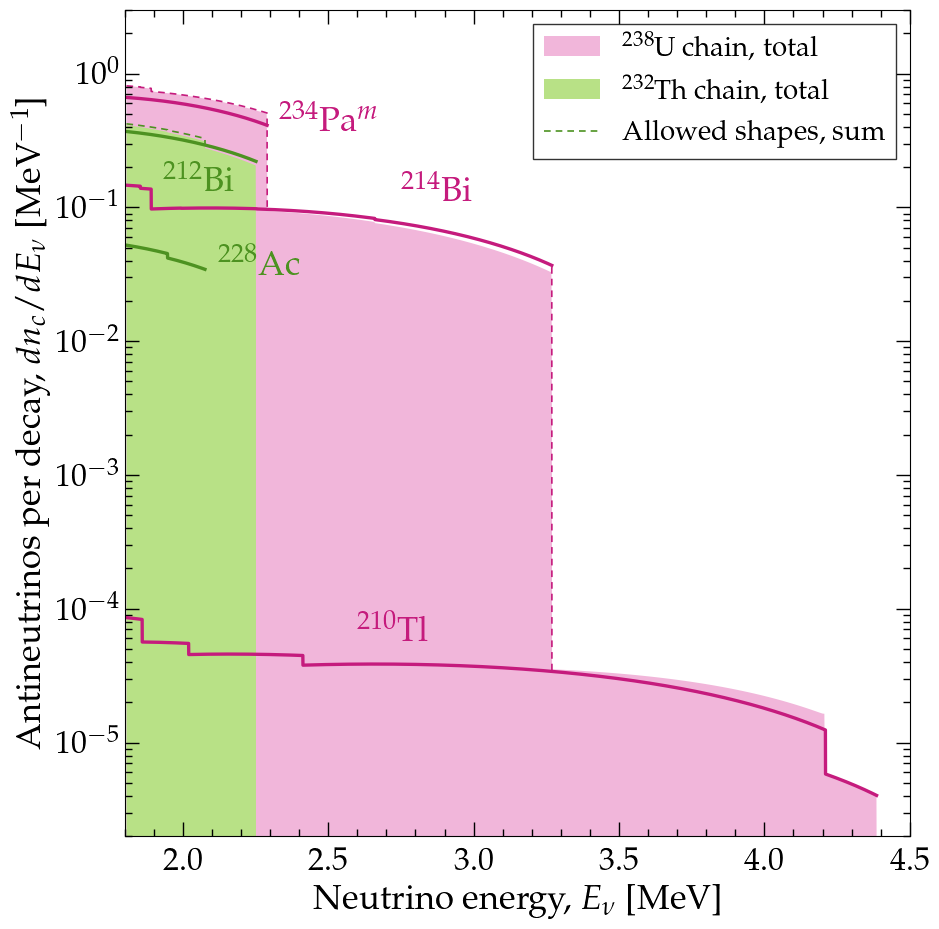

234Pa_m   68.91% of its chain's yield above the threshold
214Bi     31.07% of its chain's yield above the threshold
210Tl      0.02% of its chain's yield above the threshold
212Bi     91.98% of its chain's yield above the threshold
228Ac      8.02% of its chain's yield above the threshold


In [5]:
figdata = data.use("chain_spectra")
ch = figdata.chain_spectra()
e = ch["energy"]
CHAIN_NAME = {"U238": r"$^{238}$U chain, total", "Th232": r"$^{232}$Th chain, total"}
#: Each nuclide's label and where it sits, beside its curve.
NUCLIDE = {"234Pa_m": (r"$^{234}$Pa$^m$", 2.33, 0.42), "214Bi": (r"$^{214}$Bi", 2.75, 0.125),
           "210Tl": (r"$^{210}$Tl", 2.6, 6.5e-5), "212Bi": (r"$^{212}$Bi", 1.93, 0.15),
           "228Ac": (r"$^{228}$Ac", 2.12, 0.036)}

fig, ax = plt.subplots(figsize=(10.0, 10.0))
for chain in ("U238", "Th232"):                       # thorium in front: its total is the lower one
    total = ch["total"][chain]                        # [Sp24]'s tables, as the fits take them
    ax.fill_between(e, 1e-9, total, where=total > 0, color=CHAIN_FILL[chain], lw=0, zorder=0,
                    label=CHAIN_NAME[chain])
    allowed = ch["total_allowed"][chain]              # the nuclides' sum, every branch allowed
    on = allowed > 0
    ax.plot(e[on], allowed[on], color=CHAIN_LINE[chain], lw=1.2, ls=(0, (4, 3)), zorder=1,
            label="Allowed shapes, sum" if chain == "Th232" else None)
for chain, parts in ch["by_nuclide"].items():
    for nuclide, s in parts.items():
        on = s > 0
        ax.plot(e[on], s[on], color=CHAIN_LINE[chain], lw=2.4)
        text, x, y = NUCLIDE[nuclide]
        ax.text(x, y, text, color=CHAIN_LINE[chain], fontsize=LABEL_SIZE, ha="left", va="center")
ax.set_yscale("log")
ax.set_xlim(1.8, 4.5)
ax.set_ylim(2e-6, 3.0)
ax.xaxis.set_major_locator(MultipleLocator(0.5))
ax.xaxis.set_minor_locator(MultipleLocator(0.1))
ax.set_xlabel(r"Neutrino energy, $E_\nu$ [MeV]")
ax.set_ylabel(r"Antineutrinos per decay, $dn_c/dE_\nu$ [MeV$^{-1}$]")
ax.legend(loc="upper right", fontsize=LEGEND_SIZE, frameon=True, edgecolor="k", fancybox=False)
save(fig, "chain_spectra")
plt.show()

for nuclide, share in ch["share"].items():
    print(f"{nuclide:8s} {100 * share:6.2f}% of its chain's yield above the threshold")

## Figure 5

Where geoneutrinos come from: a cut through the Earth, with the detector at Gran Sasso, the site of Borexino.

Data: `data/geoneutrino_schematic.json`.

wrote figures/geoneutrino_schematic.pdf


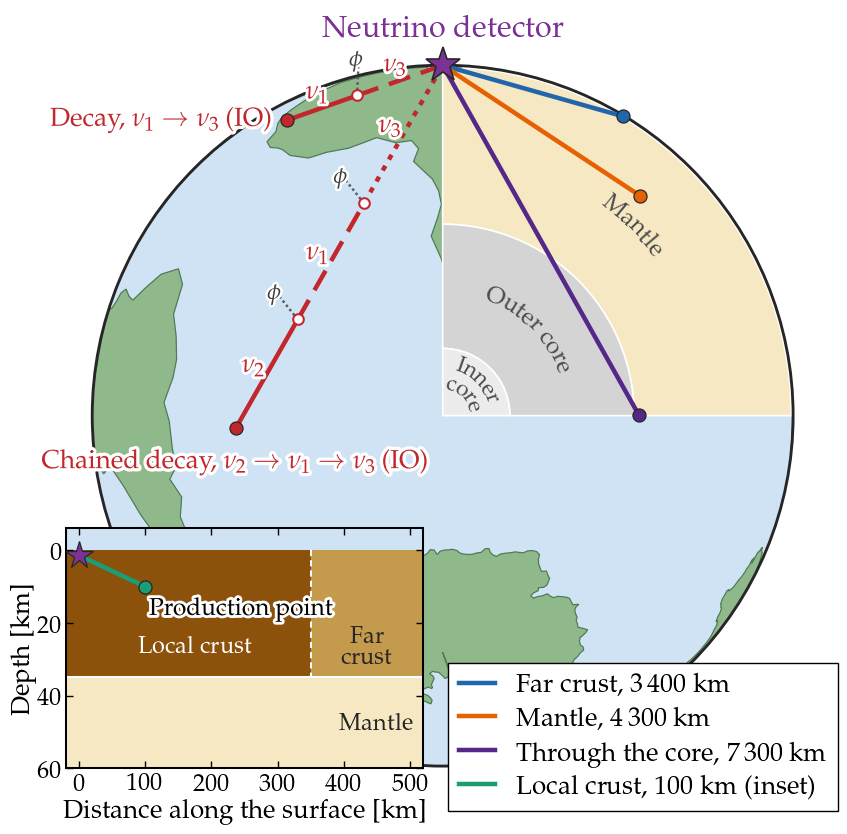

In [6]:
figdata = data.use("geoneutrino_schematic")
import matplotlib.patheffects as pe
from matplotlib.patches import Polygon, Rectangle, Wedge

CRUST_R_INNER_KM = helpers.CRUST_R_INNER_KM; LOCAL_CRUST_MAX_KM = helpers.LOCAL_CRUST_MAX_KM; MANTLE_R_INNER_KM = helpers.MANTLE_R_INNER_KM

R = figdata.R_EARTH_KM
#: Every size of the Mag(nu)s figure, scaled from its 3.4-inch column to this 10-inch figure.
SCALE = 10.0 / 3.4
#: The chords' colors and names, as the Mag(nu)s figure has them.
#: Red is kept for decay, as in every other figure: the chord through the core is violet here.
CHORD_COLORS = {"local": "#1b9e77", "far_crust": "#2166ac", "mantle": "#e66101", "core": "#542788"}
CHORD_LABELS = {"local": r"Local crust, 100 km (inset)", "far_crust": r"Far crust, 3\,400 km",
                "mantle": r"Mantle, 4\,300 km", "core": r"Through the core, 7\,300 km"}
INK, STAR = "0.15", "#7b3294"
#: Two chords reaching the detector from the left, through the side not cut away, each with a
#: decay on the way, in channels the paper limits: a direct one, nu_1 -> nu_3, and a chained one,
#: nu_2 -> nu_1 -> nu_3, both in inverted ordering.  Each: the production point's depth and
#: distance in km, the state on each stretch from the production point on, and the fractions of
#: the way at which each decay happens.
DECAY_CHORDS = (("direct", 300.0, 3000.0, (r"$\nu_1$", r"$\nu_3$"), (0.45,)),
                ("chain", 2600.0, 7600.0, (r"$\nu_2$", r"$\nu_1$", r"$\nu_3$"), (0.3, 0.62)))
DECAY_LABELS = {"direct": r"Decay, $\nu_1\to\nu_3$ (IO)",
                "chain": r"Chained decay, $\nu_2\to\nu_1\to\nu_3$ (IO)"}
#: Where each decay's name sits, by its production point: offset in Earth radii, and alignment.
DECAY_LABEL_PLACES = {"direct": ((-0.04, 0.0), "right", "center"), "chain": ((0.0, -0.06), "center", "top")}
#: The stretches after each decay, dashed and then dotted, so that each state reads as its own.
DECAY_STYLES = ("-", (0, (5, 2.5)), (0, (1.2, 1.6)))
#: The core, which holds no uranium or thorium in the model: inner, outer.
CORE_COLORS = ("#ececec", "#d4d4d4")


def curved_text(ax, text, radius, theta_deg, fontsize, color):
    """Text along the arc of a layer, one character at a time, each turned to the arc's tangent."""
    fig = ax.figure
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()

    def width(s):
        t = ax.text(0, 0, s, fontsize=fontsize)
        w = t.get_window_extent(renderer).width
        t.remove()
        return w

    space = width("a b") - width("ab")
    widths = [space if ch == " " else width(ch) for ch in text]
    per_unit = ax.transData.transform((1, 0))[0] - ax.transData.transform((0, 0))[0]
    angles = np.array(widths) / per_unit / radius
    a = np.deg2rad(theta_deg) + angles.sum() / 2.0
    for ch, da in zip(text, angles):
        middle = a - da / 2.0
        ax.text(radius * np.cos(middle), radius * np.sin(middle), ch, fontsize=fontsize, color=color, ha="center",
                va="center", rotation=np.degrees(middle) - 90.0, rotation_mode="anchor", zorder=7)
        a -= da


fig, ax = plt.subplots(figsize=(10.0, 10.2))
ax.set_aspect("equal")
ax.axis("off")
ax.set_xlim(-1.12, 1.12)
ax.set_ylim(-1.12, 1.16)
surface = Wedge((0, 0), 1.0, 90.0, 360.0, facecolor="#cfe3f5", edgecolor="none", zorder=1)
ax.add_patch(surface)
for ring in helpers.globe_rings(figdata.land_outlines(), *figdata.SCHEMATIC_SITE[:2]):
    land = Polygon(ring, closed=True, facecolor="#8fb98a", edgecolor="#4f7a55", lw=0.3 * SCALE, zorder=2)
    ax.add_patch(land)
    land.set_clip_path(surface)
# The cut: the far crust, the mantle and the core, then the local crust next to the detector.
for r0, r1, color in ((CRUST_R_INNER_KM, R, RESERVOIR_COLORS["crust_roc"]),
                      (MANTLE_R_INNER_KM, CRUST_R_INNER_KM, RESERVOIR_COLORS["mantle"]),
                      (figdata.INNER_CORE_KM, MANTLE_R_INNER_KM, CORE_COLORS[1]), (0.0, figdata.INNER_CORE_KM, CORE_COLORS[0])):
    ax.add_patch(Wedge((0, 0), r1 / R, 0.0, 90.0, width=(r1 - r0) / R, facecolor=color, edgecolor="white",
                       lw=0.4 * SCALE, zorder=3))
arc = np.degrees(LOCAL_CRUST_MAX_KM / R)
ax.add_patch(Wedge((0, 0), 1.0, 90.0 - arc, 90.0, width=(R - CRUST_R_INNER_KM) / R,
                   facecolor=RESERVOIR_COLORS["crust_local"], edgecolor="none", zorder=4))
ax.add_patch(Wedge((0, 0), 1.0, 0.0, 360.0, facecolor="none", edgecolor=INK, lw=0.7 * SCALE, zorder=6))
curved_text(ax, "Inner", 0.148, 45.0, 5.6 * SCALE, "0.3")
curved_text(ax, "core", 0.092, 45.0, 5.6 * SCALE, "0.3")
curved_text(ax, "Outer core", 0.37, 45.0, 6.0 * SCALE, "0.3")
curved_text(ax, "Mantle", 0.77, 45.0, 6.0 * SCALE, "0.3")
detector_y = (R - figdata.SCHEMATIC_SITE[2]) / R
ax.plot([0.0], [1.0], marker="*", ms=9 * SCALE, color=STAR, mec=INK, mew=0.4 * SCALE, zorder=8)
# The site is Gran Sasso, Borexino's; the label names the detector generically.
ax.text(0.0, 1.055, "Neutrino detector", fontsize=7.5 * SCALE, ha="center", va="bottom", color=STAR, zorder=8)
for key, depth, distance in figdata.SCHEMATIC_POINTS:
    if key == "local":
        continue
    x, y = helpers.production_point(depth, distance)
    ax.plot([0.0, x], [detector_y, y], color=CHORD_COLORS[key], lw=1.1 * SCALE, zorder=7)
    ax.plot([x], [y], marker="o", ms=3.2 * SCALE, color=CHORD_COLORS[key], mec=INK, mew=0.3 * SCALE, zorder=8)
# The decays, on the side not cut away: each stretch named by the state on it, each decay marked
# with the scalar it emits.
for key, depth, distance, states, fractions in DECAY_CHORDS:
    x, y = helpers.production_point(depth, distance)
    start, end = np.array([-x, y]), np.array([0.0, detector_y])
    along = end - start
    normal = np.array([-along[1], along[0]]) / np.hypot(*along)
    if normal[0] > 0:
        normal = -normal                            # the side away from the cut
    stops = [0.0] + list(fractions) + [1.0]
    for i, state in enumerate(states):
        a, b = start + stops[i] * along, start + stops[i + 1] * along
        ax.plot([a[0], b[0]], [a[1], b[1]], color=COLORS[TAU], lw=1.1 * SCALE, ls=DECAY_STYLES[i], zorder=7,
                solid_capstyle="butt")
        middle = 0.5 * (a + b) + 0.045 * normal
        ax.text(*middle, state, fontsize=6.4 * SCALE, ha="center", va="center", color=COLORS[TAU], zorder=9,
                path_effects=[pe.withStroke(linewidth=1.4 * SCALE, foreground="white")])
    for f in fractions:
        vertex = start + f * along
        tip = vertex + 0.075 * normal + 0.03 * along / np.hypot(*along)
        ax.plot([vertex[0], tip[0]], [vertex[1], tip[1]], color="0.35", lw=0.6 * SCALE, ls=(0, (1, 1.2)), zorder=7)
        ax.text(*(tip + 0.02 * normal), r"$\phi$", fontsize=5.6 * SCALE, ha="center", va="center", color="0.25",
                zorder=9, path_effects=[pe.withStroke(linewidth=1.2 * SCALE, foreground="white")])
        ax.plot(*vertex, marker="o", ms=2.6 * SCALE, mfc="white", mec=COLORS[TAU], mew=0.5 * SCALE, zorder=8)
    ax.plot(*start, marker="o", ms=3.2 * SCALE, color=COLORS[TAU], mec=INK, mew=0.3 * SCALE, zorder=8)
    (dx, dy), ha, va = DECAY_LABEL_PLACES[key]
    ax.text(start[0] + dx, start[1] + dy, DECAY_LABELS[key], fontsize=6.4 * SCALE, ha=ha, va=va, color=COLORS[TAU],
            zorder=9, path_effects=[pe.withStroke(linewidth=1.6 * SCALE, foreground="white")])
handles = [Line2D([], [], color=CHORD_COLORS[k], lw=1.1 * SCALE) for k in ("far_crust", "mantle", "core", "local")]
names = [CHORD_LABELS[k] for k in ("far_crust", "mantle", "core", "local")]
legend = ax.legend(handles, names, loc="lower right",
                   bbox_to_anchor=(1.02, -0.02), fontsize=6.4 * SCALE, handlelength=1.4, frameon=True, borderpad=0.4,
                   labelspacing=0.3, framealpha=1.0, facecolor="white", edgecolor="black", fancybox=False)
legend.set_zorder(30)
# The inset: the crust near the detector, to scale in distance and stretched in depth, split where
# the local crust ends.
inset = ax.inset_axes([0.02, 0.05, 0.455, 0.30], zorder=25)
inset.set_xlim(-20.0, 520.0)
inset.set_ylim(60.0, -6.0)
crust_depth = R - CRUST_R_INNER_KM
for x0, x1, y0, y1, color in ((-20.0, 520.0, -6.0, 0.0, "#cfe3f5"),
                              (-20.0, LOCAL_CRUST_MAX_KM, 0.0, crust_depth, RESERVOIR_COLORS["crust_local"]),
                              (LOCAL_CRUST_MAX_KM, 520.0, 0.0, crust_depth, RESERVOIR_COLORS["crust_roc"]),
                              (-20.0, 520.0, crust_depth, 60.0, RESERVOIR_COLORS["mantle"])):
    inset.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, facecolor=color, edgecolor="none", zorder=1))
inset.axhline(crust_depth, color="white", lw=0.5 * SCALE, zorder=2)
inset.plot([LOCAL_CRUST_MAX_KM] * 2, [0.0, crust_depth], color="white", lw=0.5 * SCALE, ls=(0, (3, 2)), zorder=2)
inset.text(175.0, 27.0, "Local crust", fontsize=5.8 * SCALE, ha="center", va="center", color="white", zorder=4)
inset.text(435.0, 27.0, "Far\ncrust", fontsize=5.8 * SCALE, ha="center", va="center", color="0.15", zorder=4,
           linespacing=0.9)
inset.text(505.0, 48.0, "Mantle", fontsize=5.8 * SCALE, ha="right", va="center", color="0.15", zorder=4)
depth_local = dict((k, d) for k, d, _ in figdata.SCHEMATIC_POINTS)["local"]
distance_local = dict((k, l) for k, _, l in figdata.SCHEMATIC_POINTS)["local"]
x_local = np.sqrt(distance_local ** 2 - (depth_local - figdata.SCHEMATIC_SITE[2]) ** 2)
inset.plot([0.0], [figdata.SCHEMATIC_SITE[2]], marker="*", ms=7 * SCALE, color=STAR, mec=INK, mew=0.3 * SCALE, zorder=6)
inset.plot([0.0, x_local], [figdata.SCHEMATIC_SITE[2], depth_local], color=CHORD_COLORS["local"], lw=1.1 * SCALE, zorder=5)
inset.plot([x_local], [depth_local], marker="o", ms=3.2 * SCALE, color=CHORD_COLORS["local"], mec=INK,
           mew=0.3 * SCALE, zorder=6)
inset.text(x_local + 6.0, depth_local + 3.0, "Production point", fontsize=6.0 * SCALE, color="black", ha="left",
           va="top", zorder=6, path_effects=[pe.withStroke(linewidth=1.4 * SCALE, foreground="white")])
inset.set_xlabel("Distance along the surface [km]", fontsize=6.4 * SCALE, labelpad=1.0)
inset.set_ylabel("Depth [km]", fontsize=6.4 * SCALE, labelpad=1.0)
inset.tick_params(labelsize=6.0 * SCALE, pad=1.0 * SCALE, length=1.8 * SCALE)
inset.set_xticks([0, 100, 200, 300, 400, 500])
inset.set_yticks([0, 20, 40, 60])
for side in inset.spines.values():
    side.set_linewidth(0.5 * SCALE)
save(fig, "geoneutrino_schematic")
plt.show()

## Figure 6

Geoneutrino flux at Borexino, with and without decay.

Data: `data/neutrino_spectrum.json`.

wrote figures/neutrino_spectrum.pdf


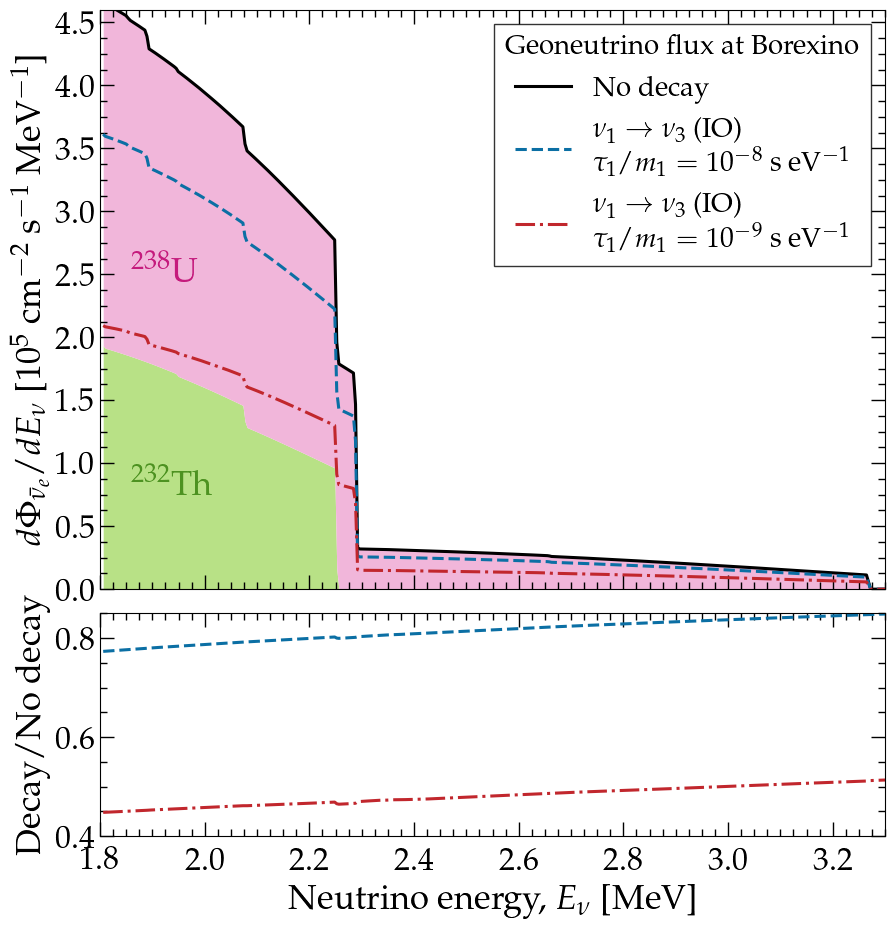

flux above threshold without decay: 1.977e+05 cm^-2 s^-1
  tau_1/m_1 = 1e-8 s eV^-1: 0.792 of it
  tau_1/m_1 = 1e-9 s eV^-1: 0.461 of it


In [7]:
figdata = data.use("neutrino_spectrum")
nu = figdata.neutrino_spectrum(SITE, TAUS)
e, unit = nu["energy"], 1e5
de = e[1] - e[0]

fig, (ax, low) = plt.subplots(2, 1, figsize=(10.0, 10.0), sharex=True,
                              gridspec_kw={"height_ratios": [2.6, 1.0], "hspace": 0.06})
th, total = nu["by_chain"]["Th232"] / unit, nu["no_decay"] / unit
ax.fill_between(e, 0.0, th, color=CHAIN_FILL["Th232"], lw=0)
ax.fill_between(e, th, total, color=CHAIN_FILL["U238"], lw=0)
ax.plot(e, total, color=COLORS[None], ls=DASHES[None], lw=2.2, label="No decay")
for lt in TAUS:
    ax.plot(e, nu["decay"][lt] / unit, color=COLORS[lt], ls=DASHES[lt], lw=2.2, label=CHANNEL + "\n" + tau_label(lt))
ax.text(1.86, 0.8, r"$^{232}$Th", ha="left", va="center", fontsize=LABEL_SIZE, color=CHAIN_LINE["Th232"])
ax.text(1.86, 2.5, r"$^{238}$U", ha="left", va="center", fontsize=LABEL_SIZE, color=CHAIN_LINE["U238"])
ax.set_ylim(0.0, 4.6)
ax.yaxis.set_major_locator(MultipleLocator(0.5))
ax.set_ylabel(r"$d\Phi_{\bar\nu_e}/dE_\nu$ [$10^5$ cm$^{-2}$ s$^{-1}$ MeV$^{-1}$]")
ax.legend(loc="upper right", title="Geoneutrino flux at Borexino", fontsize=LEGEND_SIZE, title_fontsize=LEGEND_SIZE,
          frameon=True, edgecolor="k", fancybox=False)
for lt in TAUS:
    alive = nu["no_decay"] > 0
    low.plot(e[alive], nu["decay"][lt][alive] / nu["no_decay"][alive], color=COLORS[lt], ls=DASHES[lt], lw=2.2)
low.set_ylim(0.4, 0.85)
low.yaxis.set_major_locator(MultipleLocator(0.2))
low.yaxis.set_minor_locator(MultipleLocator(0.05))
low.set_xlim(1.8, 3.3)
low.xaxis.set_major_locator(MultipleLocator(0.2))
low.xaxis.set_minor_locator(MultipleLocator(0.025))
low.set_ylabel("Decay/No decay")
low.set_xlabel(r"Neutrino energy, $E_\nu$ [MeV]")
minor_ticks(ax, x=False)
fig.align_ylabels((ax, low))
save(fig, "neutrino_spectrum")
plt.show()

full = nu["no_decay"].sum() * de
print(f"flux above threshold without decay: {full:.3e} cm^-2 s^-1")
for lt in TAUS:
    print(f"  tau_1/m_1 = 1e{int(lt)} s eV^-1: {nu['decay'][lt].sum() * de / full:.3f} of it")

## Figure 7

Geoneutrino flux at Borexino by the distance it travels, reservoir by reservoir, with and without decay.

Data: `data/flux_by_distance.json`.

wrote figures/flux_by_distance.pdf


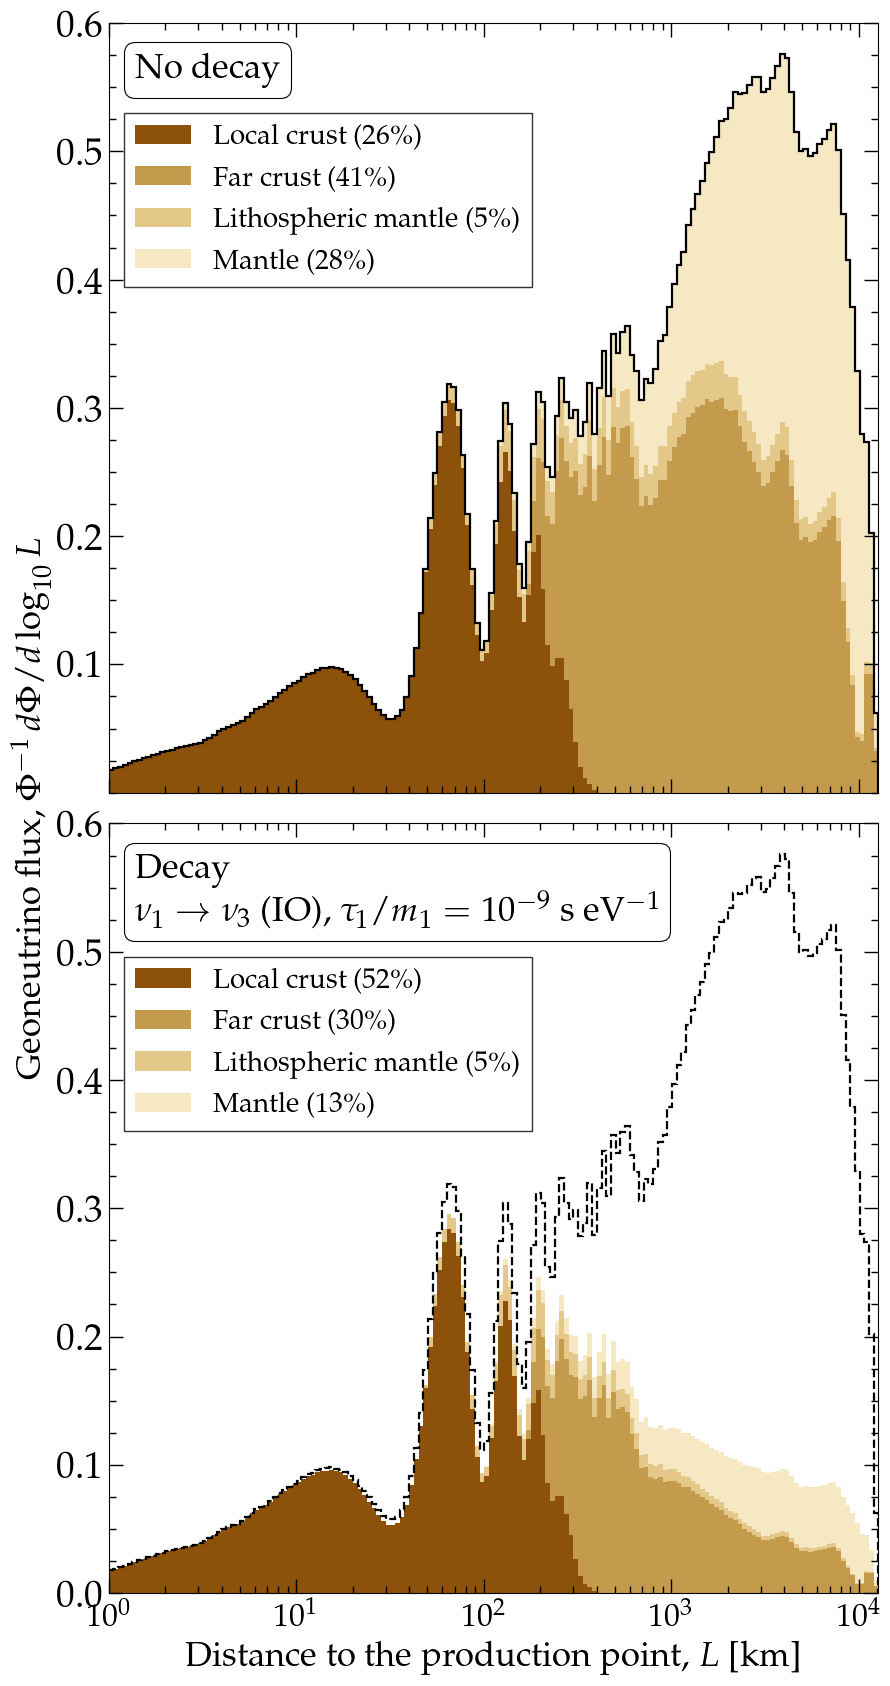

no decay: Local crust 0.261, Far crust 0.406, Lithospheric mantle 0.051, Mantle 0.282; all 1.000 of Phi
tau_1/m_1 = 1e-9 s eV^-1: Local crust 0.237, Far crust 0.136, Lithospheric mantle 0.024, Mantle 0.062; all 0.459 of Phi
share of its own flux each reservoir keeps with decay: Local crust 0.908, Far crust 0.335, Lithospheric mantle 0.470, Mantle 0.219
share of the flux with decay: Local crust 0.516, Far crust 0.296, Lithospheric mantle 0.053, Mantle 0.135


In [8]:
figdata = data.use("flux_by_distance")
dist = figdata.flux_by_distance(SITE, (TAU,))
edges = dist["edges"]
per_decade = np.diff(np.log10(edges))
#: The flux without decay, which normalizes both panels.
PHI = sum(v.sum() for v in dist["no_decay"].values())

from matplotlib.offsetbox import AnchoredText

#: The left edge, in axes fractions, of each panel's label and of its legend below it.
LEFT_EDGE = 0.02

fig, axes = plt.subplots(2, 1, figsize=(10.0, 19.0), sharex=True, gridspec_kw={"hspace": 0.04})
panels = ((axes[0], dist["no_decay"], "No decay"),
          (axes[1], dist["decay"][TAU], "Decay\n" + CHANNEL + ", " + tau_label(TAU)))
tags = []
for ax, which, name in panels:
    base = np.zeros(per_decade.size)
    # Each legend gives each reservoir's share of the flux in its own panel, so it adds up to 100%.
    total = sum(v.sum() for v in which.values())
    for res, label in figdata.RESERVOIRS.items():
        top = base + which[res] / per_decade / PHI
        ax.stairs(top, edges, baseline=base, fill=True, color=RESERVOIR_COLORS[res], lw=0,
                  label=f"{label} ({100 * which[res].sum() / total:.0f}\\%)")
        base = top
    ax.stairs(sum(dist["no_decay"].values()) / per_decade / PHI, edges, color="k", lw=1.6,
              ls="-" if which is dist["no_decay"] else "--")
    label = AnchoredText(name, loc="upper left", bbox_to_anchor=(LEFT_EDGE, 0.975), bbox_transform=ax.transAxes,
                         borderpad=0.0, pad=0.3, prop=dict(size=LABEL_SIZE), frameon=True)
    label.patch.set_boxstyle("round,pad=0.0,rounding_size=0.3")
    label.patch.set_edgecolor("k")
    label.patch.set_linewidth(0.8)
    ax.add_artist(label)
    tags.append(label)
    ax.set_box_aspect(1.0)
    ax.tick_params(axis="y", labelsize=27)
    minor_ticks(ax, x=False)
axes[1].set_xscale("log")
axes[1].set_xlim(1.0, edges[-1])
for ax, lowest in zip(axes, (0.1, 0.0)):
    ax.set_ylim(0.0, 0.6)
    ax.set_yticks(np.arange(lowest, 0.61, 0.1))
axes[1].set_xlabel(r"Distance to the production point, $L$ [km]")
# Each legend right below its panel's label, their left edges aligned: placed once the labels are drawn.
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
for ax, label in zip(axes, tags):
    bottom = ax.transAxes.inverted().transform((0.0, label.get_window_extent(renderer).y0))[1]
    ax.legend(loc="upper left", bbox_to_anchor=(LEFT_EDGE, bottom - 0.02), borderaxespad=0.0, fontsize=LEGEND_SIZE,
              frameon=True, edgecolor="k", fancybox=False)
stack_ylabel(axes, r"Geoneutrino flux, $\Phi^{-1}\, d\Phi/d\log_{10} L$", on=axes[0])
save(fig, "flux_by_distance")
plt.show()

for name, which in (("no decay", dist["no_decay"]), (f"tau_1/m_1 = 1e{int(TAU)} s eV^-1", dist["decay"][TAU])):
    print(f"{name}: " + ", ".join(f"{figdata.RESERVOIRS[r]} {which[r].sum() / PHI:.3f}" for r in figdata.RESERVOIRS)
          + f"; all {sum(v.sum() for v in which.values()) / PHI:.3f} of Phi")
print("share of its own flux each reservoir keeps with decay: "
      + ", ".join(f"{figdata.RESERVOIRS[r]} {dist['decay'][TAU][r].sum() / dist['no_decay'][r].sum():.3f}" for r in figdata.RESERVOIRS))
print("share of the flux with decay: " + ", ".join(
    f"{figdata.RESERVOIRS[r]} {dist['decay'][TAU][r].sum() / sum(v.sum() for v in dist['decay'][TAU].values()):.3f}"
    for r in figdata.RESERVOIRS))

## Figure 8

Reactor antineutrinos with and without decay: the flux at SNO+, core by core, and the fraction of the reactor antineutrinos at each experiment that survives decay.

Data: `data/reactor_decay.json`.

wrote figures/reactor_decay.pdf


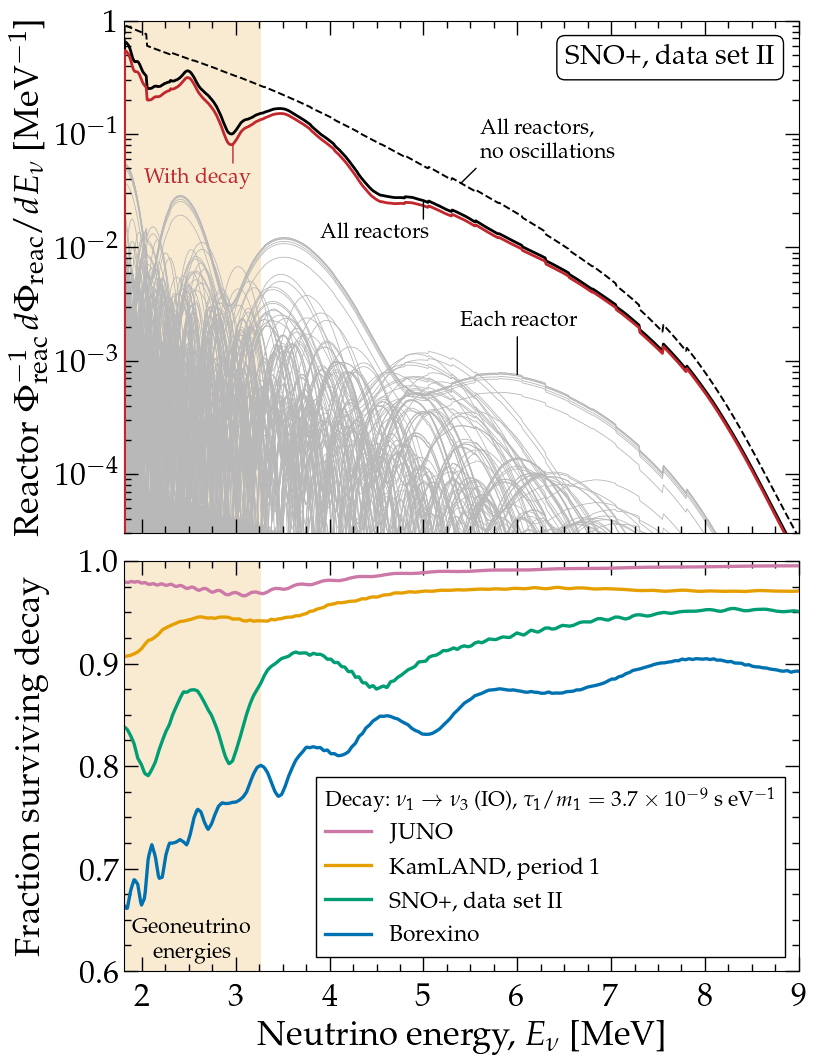

In [9]:
figdata = data.use("reactor_decay")
from matplotlib.ticker import FuncFormatter

#: The lifetime drawn: all four's limit on tau_1/m_1 with the radiogenic power free, s/eV.
TAU_LIMIT = plot_money.our_limits("io_n1_n3", "log10_tau1_over_m1")[0]
mantissa, exponent = f"{TAU_LIMIT:.1e}".split("e")
TAU_LABEL = rf"$\tau_1/m_1 = {mantissa}\times10^{{{int(exponent)}}}$ s eV$^{{-1}}$"
#: The flux, as section 3's figures show the geoneutrinos, not the spectrum of IBD events.
rd = figdata.reactor_spectra(tau1_over_m1=TAU_LIMIT, flux=True)
e = rd["energy"]
sets = {d["label"]: d for d in rd["data_sets"]}
#: The data set of the top panel, and the bottom panel's curves from the top one down.
EXAMPLE = ("SNO+ (2026)\nData set II", "SNO+, data set II")
SURVIVING = (("JUNO (2026)", "JUNO", "#CC79A7"), ("KamLAND (2022)\nPeriod 1", "KamLAND, period 1", "#E69F00"),
             ("SNO+ (2026)\nData set II", "SNO+, data set II", "#009E73"), ("Borexino (2020)", "Borexino", "#0072B2"))
GEO_END_MEV = 3.27
DECAY_RED, NOTE = "#C1272D", 15.5


def lead(ax, text, xy, xytext, relpos, color="k"):
    """A text label joined to its curve by a thin leader line, drawn from the point ``relpos`` of the text's box.

    ``xytext`` is the box's lower left corner. The positions were found by searching the rendered figure
    for places where no text touches a curve and no leader crosses one; the leader of "All reactors" meets
    the red curve only in its last pixels, where the red and black curves are 5 pixels apart.
    """
    ax.annotate(text, xy=xy, xytext=xytext, color=color, fontsize=NOTE, ha="left", va="bottom", zorder=6,
                multialignment="left",
                arrowprops=dict(arrowstyle="-", color=color, lw=1.0, shrinkA=1, shrinkB=0, relpos=relpos))


d = sets[EXAMPLE[0]]
at = lambda curve, x: float(np.interp(x, e, curve))   # noqa: E731
fig, (top, bot) = plt.subplots(2, 1, figsize=(8.6, 11.5), sharex=True,
                               gridspec_kw={"height_ratios": [1.25, 1.0], "hspace": 0.06})
for ax in (top, bot):
    ax.axvspan(e.min(), GEO_END_MEV, color="#F5DEB3", alpha=0.6, lw=0, zorder=0)
# Stored as an image, as in figure A5: the cores' lines as vectors made a 3 MB file.
for part in d["reactors"]:
    top.plot(e, part, color="0.72", lw=0.6, zorder=1, rasterized=True)
top.plot(e, d["unoscillated"], color="k", lw=1.4, ls="--", zorder=3)
top.plot(e, d["total"], color="k", lw=2.0, zorder=3)
top.plot(e, d["decayed"], color=DECAY_RED, lw=2.0, zorder=4)
top.set_yscale("log")
top.set_ylim(3e-5, 1.0)
top.yaxis.set_major_formatter(FuncFormatter(
    lambda v, _: "1" if abs(v - 1.0) < 1e-12 else rf"$10^{{{int(round(np.log10(v)))}}}$"))
top.set_ylabel(r"Reactor $\Phi_{\rm reac}^{-1}\,d\Phi_{\rm reac}/dE_\nu$ [MeV$^{-1}$]")
top.text(0.965, 0.955, EXAMPLE[1], transform=top.transAxes, ha="right", va="top", fontsize=20,
         bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", lw=1.0))
strongest = max(d["reactors"], key=lambda part: at(part, 6.0))
lead(top, "All reactors,\nno oscillations", (5.4, at(d["unoscillated"], 5.4)), (5.6005, 0.05382), (0.0, 0.0))
lead(top, "All reactors", (5.0, at(d["total"], 5.0)), (3.8955, 0.010593), (0.947, 1.0))
lead(top, "With decay", (2.97, at(d["decayed"], 2.97)), (2.02, 0.033049), (0.834, 1.0), color=DECAY_RED)
lead(top, "Each reactor", (6.0, at(strongest, 6.0)), (5.3873, 0.001772), (0.492, 0.0))

for label, name, color in SURVIVING:
    bot.plot(e, sets[label]["surviving"], color=color, lw=2.4, label=name)
legend = bot.legend(loc="lower right", fontsize=NOTE + 1, edgecolor="black", fancybox=False, framealpha=1,
                    borderaxespad=0.6, title=r"Decay: $\nu_1\to\nu_3$ (IO), " + TAU_LABEL, title_fontsize=NOTE)
legend._legend_box.align = "left"
bot.text(0.5 * (e.min() + GEO_END_MEV), 0.607, "Geoneutrino\nenergies", fontsize=NOTE, ha="center", va="bottom",
         multialignment="center", zorder=6)
bot.set_ylim(0.6, 1.0)
bot.yaxis.set_major_locator(MultipleLocator(0.1))
bot.yaxis.set_minor_locator(MultipleLocator(0.025))
bot.set_ylabel("Fraction surviving decay")
bot.set_xlabel(r"Neutrino energy, $E_\nu$ [MeV]")
bot.set_xlim(e.min(), 9.0)
bot.xaxis.set_major_locator(MultipleLocator(1.0))
bot.xaxis.set_minor_locator(MultipleLocator(0.25))
fig.align_ylabels([top, bot])
save(fig, "reactor_decay")
plt.show()

## Figure 9

JUNO's reactor antineutrinos with and without the decay of $\nu_3$, which flattens the ripple of the oscillation driven by $\Delta m^2_{31}$.

Data: `data/juno_nu3_decay.json`.

wrote figures/juno_nu3_decay.pdf


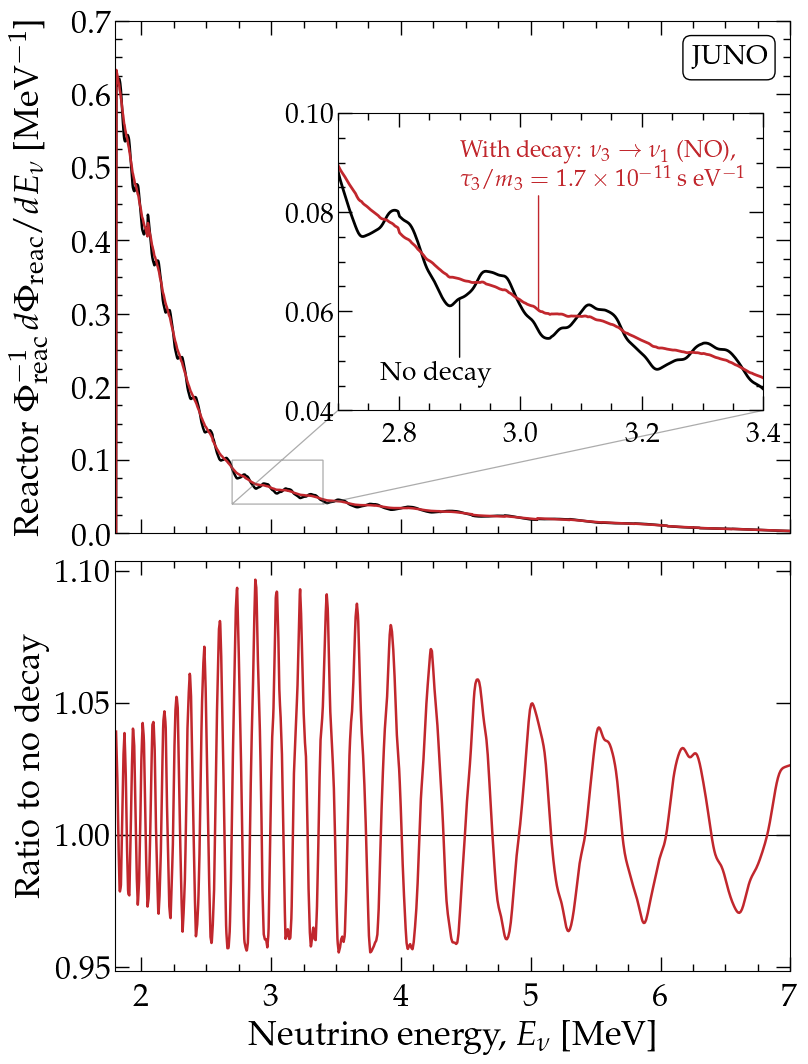

In [10]:
figdata = data.use("juno_nu3_decay")
#: The lifetime drawn: all four's limit on tau_3/m_3 for nu_3 -> nu_1 with the radiogenic power free, s/eV.
TAU3_LIMIT = plot_money.our_limits("no_n3_n1", "log10_tau3_over_m3")[0]
mantissa, exponent = f"{TAU3_LIMIT:.1e}".split("e")
#: The flux, as in section 13's figure.
ripple = figdata.juno_reactor_decay(TAU3_LIMIT, flux=True)
e = ripple["energy"]
#: The size of the curves' labels, larger than section 13's: this figure has two curves only.
CURVE_LABEL = 19.0
#: The inset's window: neutrino energy [MeV] and flux, where decay moves the flux most, by up to 10%.
WINDOW = (2.70, 3.40, 0.040, 0.100)


def lead_large(ax, text, xy, xytext, relpos, color="k", size=CURVE_LABEL):
    """A text label joined to its curve by a thin leader line, as section 13's ``lead``."""
    ax.annotate(text, xy=xy, xytext=xytext, color=color, fontsize=size, ha="left", va="bottom", zorder=6,
                multialignment="left",
                arrowprops=dict(arrowstyle="-", color=color, lw=1.0, shrinkA=1, shrinkB=0, relpos=relpos))


at = lambda curve, x: float(np.interp(x, e, curve))   # noqa: E731
fig, (top, bot) = plt.subplots(2, 1, figsize=(8.6, 11.5), sharex=True,
                               gridspec_kw={"height_ratios": [1.25, 1.0], "hspace": 0.06})
top.plot(e, ripple["total"], color="k", lw=1.8)
top.plot(e, ripple["decayed"], color=DECAY_RED, lw=1.8)
top.set_ylabel(r"Reactor $\Phi_{\rm reac}^{-1}\,d\Phi_{\rm reac}/dE_\nu$ [MeV$^{-1}$]")
top.set_ylim(0.0, 0.7)
top.yaxis.set_major_locator(MultipleLocator(0.1))
top.yaxis.set_minor_locator(MultipleLocator(0.025))
# Top right, since the flux fills the upper left corner.
top.text(0.965, 0.955, "JUNO", transform=top.transAxes, ha="right", va="top", fontsize=20,
         bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", lw=1.0))
ins = top.inset_axes([0.33, 0.24, 0.63, 0.58])
ins.plot(e, ripple["total"], color="k", lw=2.0)
ins.plot(e, ripple["decayed"], color=DECAY_RED, lw=2.0)
ins.set_xlim(WINDOW[0], WINDOW[1])
ins.set_ylim(WINDOW[2], WINDOW[3])
ins.xaxis.set_major_locator(MultipleLocator(0.2))
ins.xaxis.set_minor_locator(MultipleLocator(0.05))
ins.yaxis.set_major_locator(MultipleLocator(0.02))
ins.yaxis.set_minor_locator(MultipleLocator(0.005))
ins.tick_params(labelsize=plt.rcParams["xtick.labelsize"] - 3)
top.indicate_inset_zoom(ins, edgecolor="0.35", lw=0.9)
lead_large(ins, "No decay", (2.90, at(ripple["total"], 2.90)), (2.7696, 0.044586), (0.715, 1.0))
lead_large(ins, "With decay: " r"$\nu_3\to\nu_1$ (NO)," "\n"
           rf"$\tau_3/m_3 = {mantissa}\times10^{{{int(exponent)}}}$ s eV$^{{-1}}$",
           (3.03, at(ripple["decayed"], 3.03)), (2.9013, 0.084145), (0.274, 0.0), color=DECAY_RED,
           size=CURVE_LABEL - 2)
bot.axhline(1.0, color="k", lw=0.8)
bot.plot(e, ripple["ratio"], color=DECAY_RED, lw=1.8)
bot.set_ylabel("Ratio to no decay")
bot.set_xlabel(r"Neutrino energy, $E_\nu$ [MeV]")
bot.set_xlim(1.8, 7.0)
bot.xaxis.set_major_locator(MultipleLocator(1.0))
bot.xaxis.set_minor_locator(MultipleLocator(0.25))
fig.align_ylabels([top, bot])
save(fig, "juno_nu3_decay")
plt.show()

## Figure 10

Detected spectra of the four experiments, with and without decay, against their data.

Data: `data/event_spectra.json`.

wrote figures/event_spectra.pdf


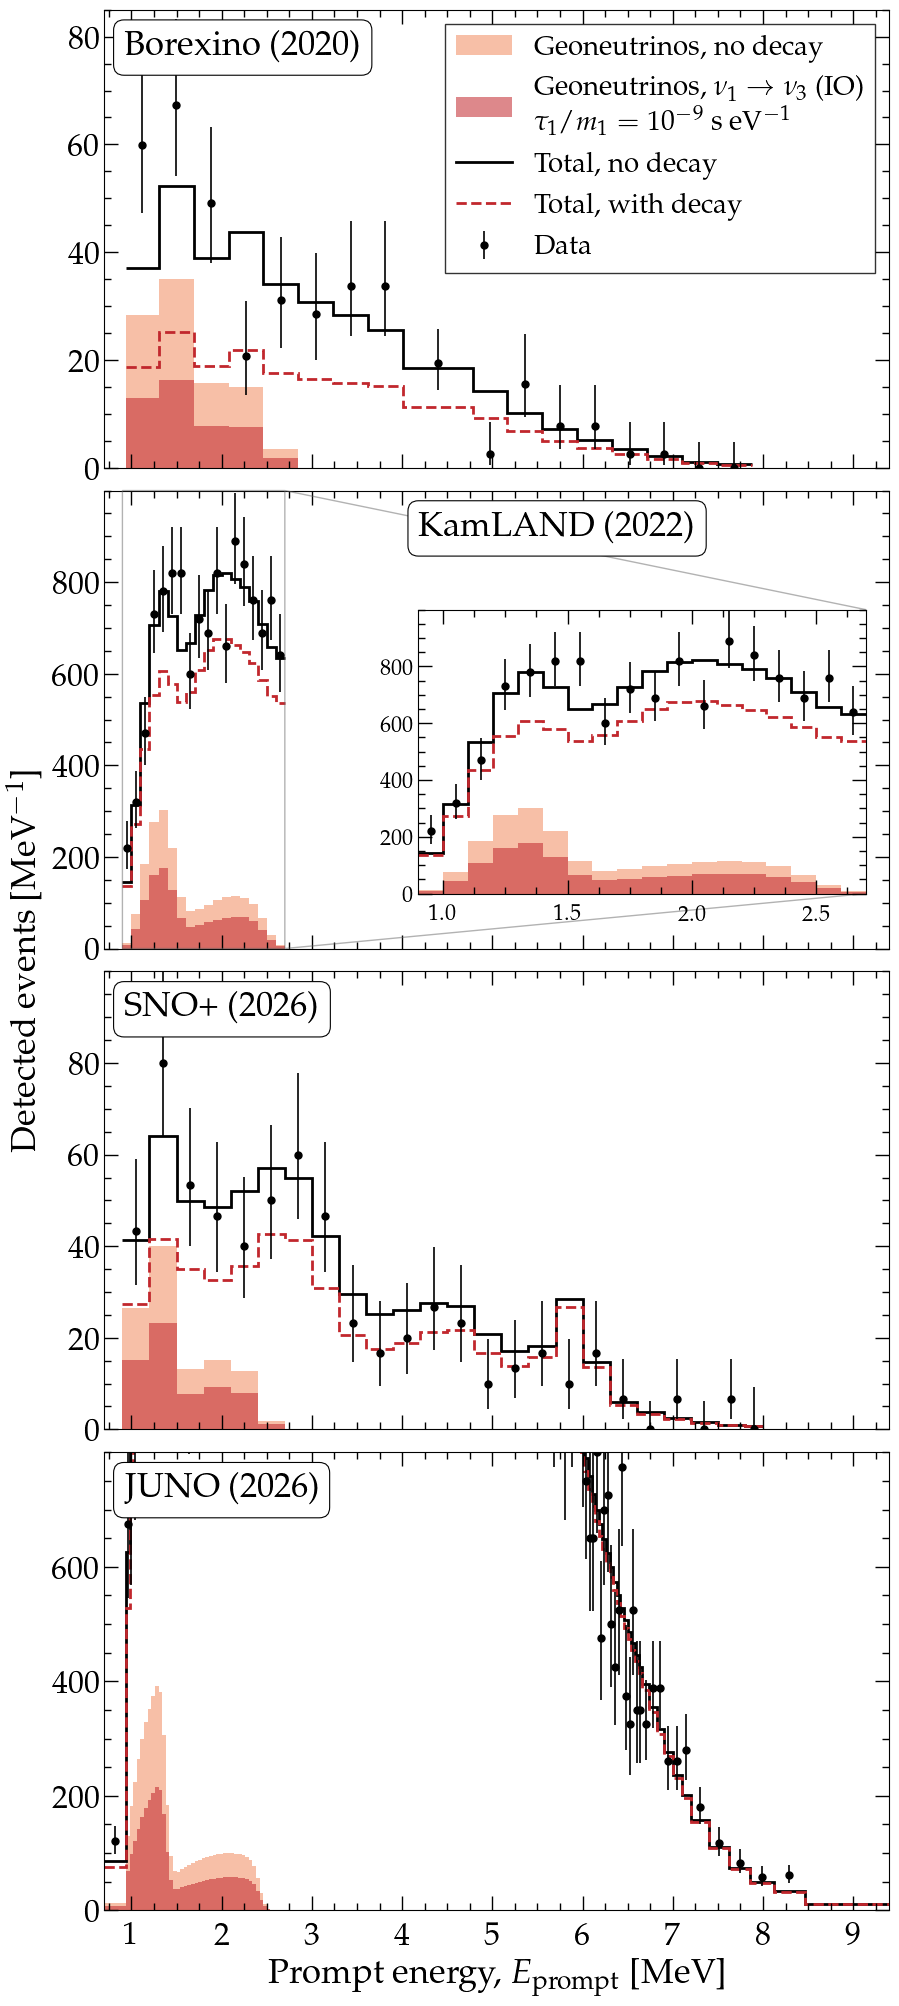

Borexino  data    154; expected without decay   143.0 (geoneutrinos   37.2), with tau_1/m_1 = 1e-9 s eV^-1    77.7 (geoneutrinos   17.7)
KamLAND   data   1223; expected without decay  1203.3 (geoneutrinos  209.0), with tau_1/m_1 = 1e-9 s eV^-1   990.3 (geoneutrinos  123.7)
SNO+      data    185; expected without decay   198.1 (geoneutrinos   32.8), with tau_1/m_1 = 1e-9 s eV^-1   146.2 (geoneutrinos   19.4)
JUNO      data   8294; expected without decay  7719.1 (geoneutrinos  229.5), with tau_1/m_1 = 1e-9 s eV^-1  7129.2 (geoneutrinos  127.4)


In [11]:
figdata = data.use("event_spectra")
spectra = {site: figdata.event_spectra(site, (TAU,)) for site in figdata.SITES}


def draw_events(ax, d, labels=False):
    """One experiment's data and its expected spectra, per MeV."""
    edges = d["edges"]
    width = np.diff(edges)
    centres = 0.5 * (edges[:-1] + edges[1:])
    ax.stairs(d["no_decay"]["geo"] / width, edges, fill=True, color="#f4a582", alpha=0.7, lw=0,
              label="Geoneutrinos, no decay" if labels else None)
    ax.stairs(d["decay"][TAU]["geo"] / width, edges, fill=True, color=COLORS[TAU], alpha=0.55, lw=0,
              label="Geoneutrinos, " + CHANNEL + "\n" + tau_label(TAU) if labels else None)
    ax.stairs(d["no_decay"]["total"] / width, edges, color=COLORS[None], lw=2.0, baseline=None,
              label="Total, no decay" if labels else None)
    ax.stairs(d["decay"][TAU]["total"] / width, edges, color=COLORS[TAU], ls="--", lw=2.0, baseline=None,
              label="Total, with decay" if labels else None)
    low, high = helpers.poisson_interval(d["observed"])
    ax.errorbar(centres, d["observed"] / width, yerr=[low / width, high / width], fmt="o", ms=5,
                color="k", lw=1.2, capsize=0, label="Data" if labels else None, zorder=5)


fig, axes = plt.subplots(4, 1, figsize=(10.0, 23.0), sharex=True, gridspec_kw={"hspace": 0.05})
for ax, site in zip(axes, figdata.SITES):
    d = spectra[site]
    draw_events(ax, d, labels=(site == "borexino"))
    ax.set_ylim(0.0, Y_TOP[site])
    ax.set_yticks(Y_TICKS[site])
    minor_ticks(ax, x=False)
    # KamLAND's data reach the top of the common range's left end, so its label sits right of them.
    tag(ax, ANALYSES[site], x=0.40 if site == "kamland" else 0.025)
    if site == "kamland":
        # KamLAND's window, 0.9-2.7 MeV, is a fifth of the common range: drawn again, zoomed.
        inset = ax.inset_axes([0.40, 0.12, 0.57, 0.62])
        draw_events(inset, d)
        inset.set_xlim(d["edges"][0], d["edges"][-1])
        inset.set_ylim(0.0, Y_TOP[site])
        inset.set_yticks(Y_TICKS[site])
        inset.tick_params(labelsize=16)
        minor_ticks(inset)
        ax.indicate_inset_zoom(inset, edgecolor="0.4")
axes[0].legend(loc="upper right", fontsize=LEGEND_SIZE, frameon=True, edgecolor="k", fancybox=False)
axes[-1].set_xlim(*X_RANGE)
energy_ticks(axes[-1])
axes[-1].set_xlabel(r"Prompt energy, $E_{\rm prompt}$ [MeV]")
stack_ylabel(axes, EVENTS_LABEL)
save(fig, "event_spectra")
plt.show()

for site, name in figdata.SITES.items():
    d = spectra[site]
    print(f"{name:9s} data {d['observed'].sum():6.0f}; expected without decay {d['no_decay']['total'].sum():7.1f} "
          f"(geoneutrinos {d['no_decay']['geo'].sum():6.1f}), with tau_1/m_1 = 1e{int(TAU)} s eV^-1 "
          f"{d['decay'][TAU]['total'].sum():7.1f} (geoneutrinos {d['decay'][TAU]['geo'].sum():6.1f})")

## Figure 11

Lower limits on $\tau_i/m_i$ from every decay channel, experiment, and Earth model. The numbers are in `data/limits.json`.

Data: `data/limits_overview.json`.

wrote figures/limits_overview.pdf


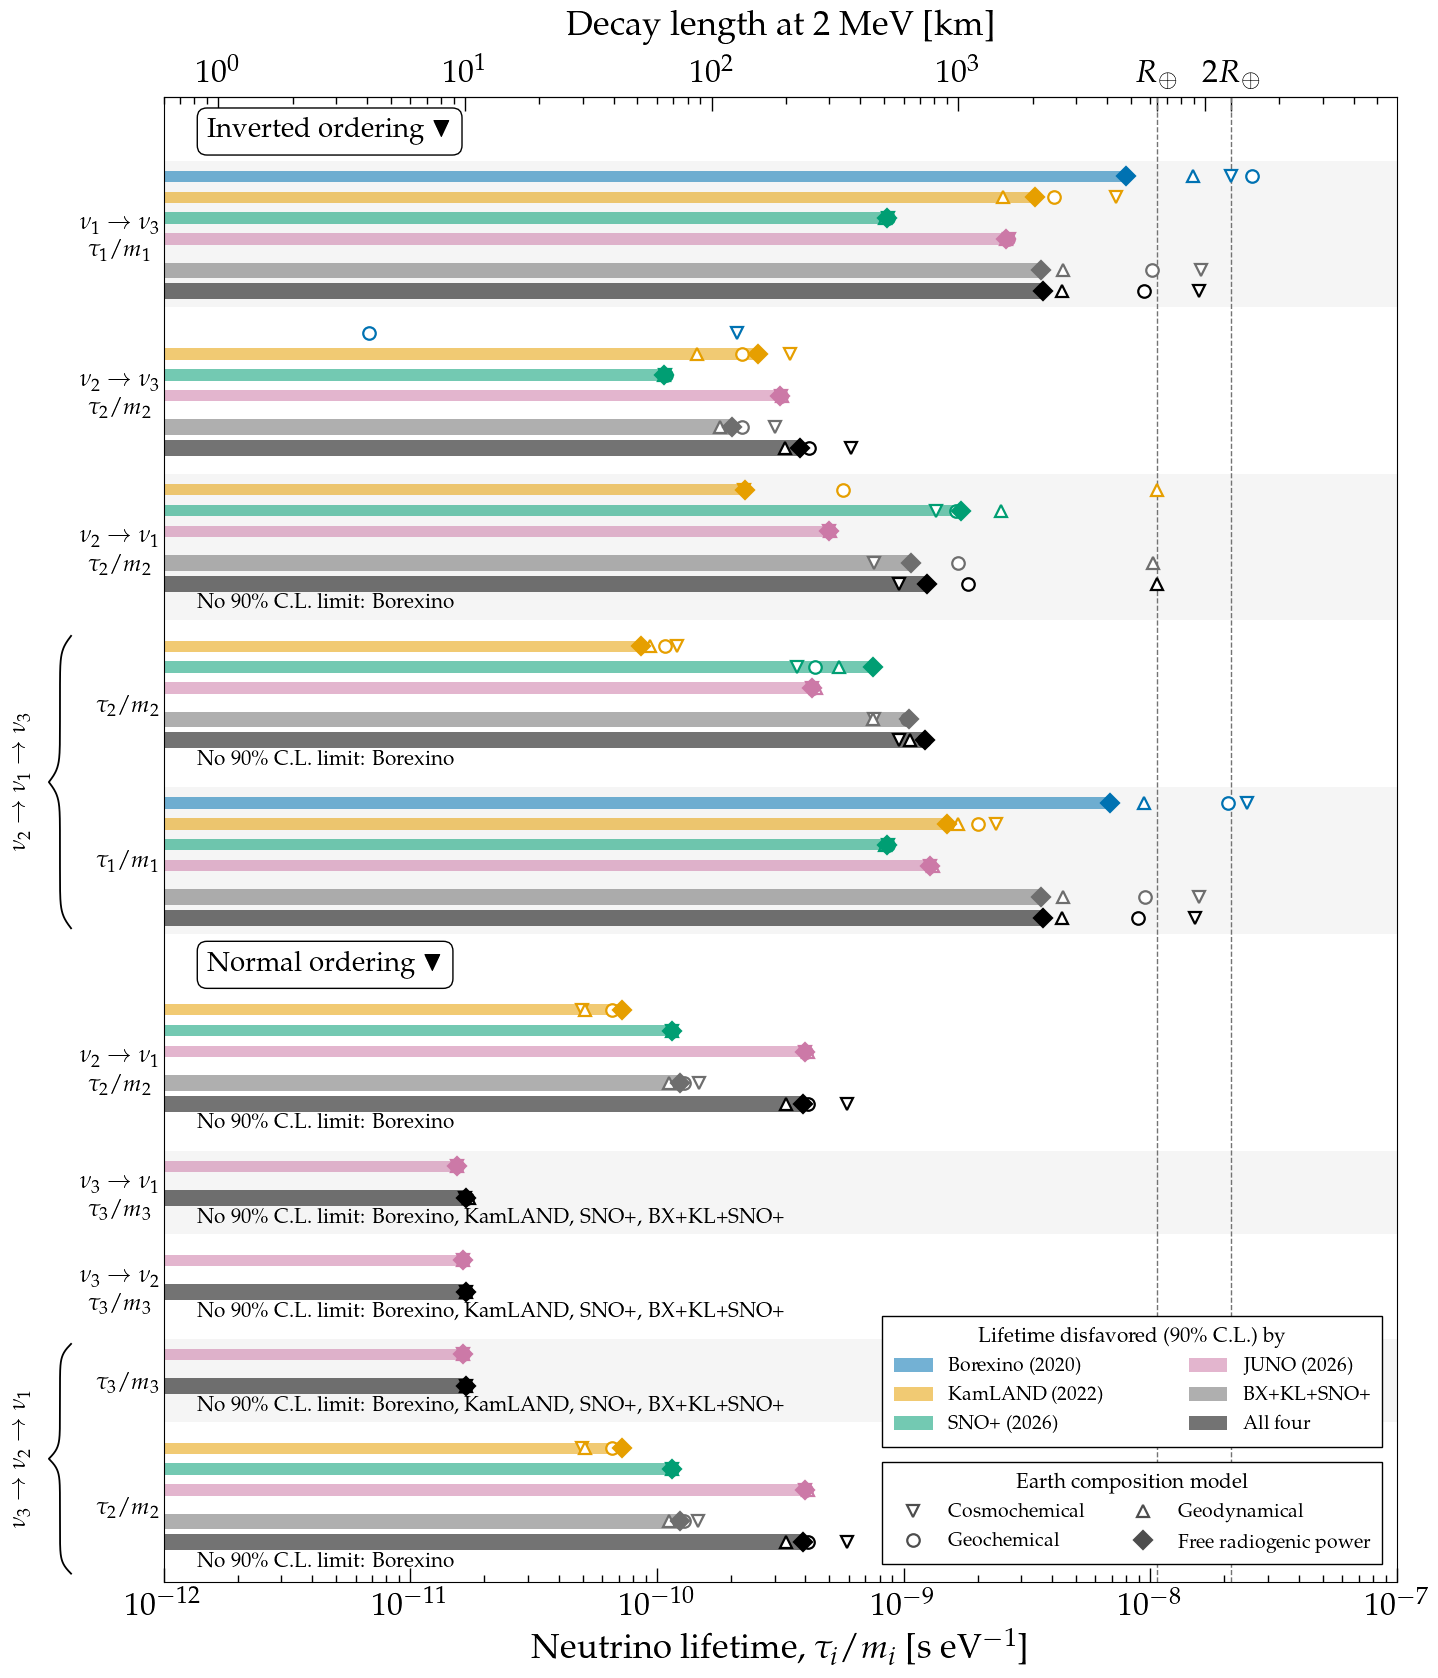

In [12]:
figdata = data.use("limits_overview")
from plotting import limits_overview as plot_limits_overview

fig = plot_limits_overview.figure()
save(fig, "limits_overview")
plt.show()

## Figure B.1

Our calculation of each experiment's detected spectrum without decay, compared with the collaboration's best fit.

Data: `data/reproduction.json`.

wrote figures/reproduction.pdf


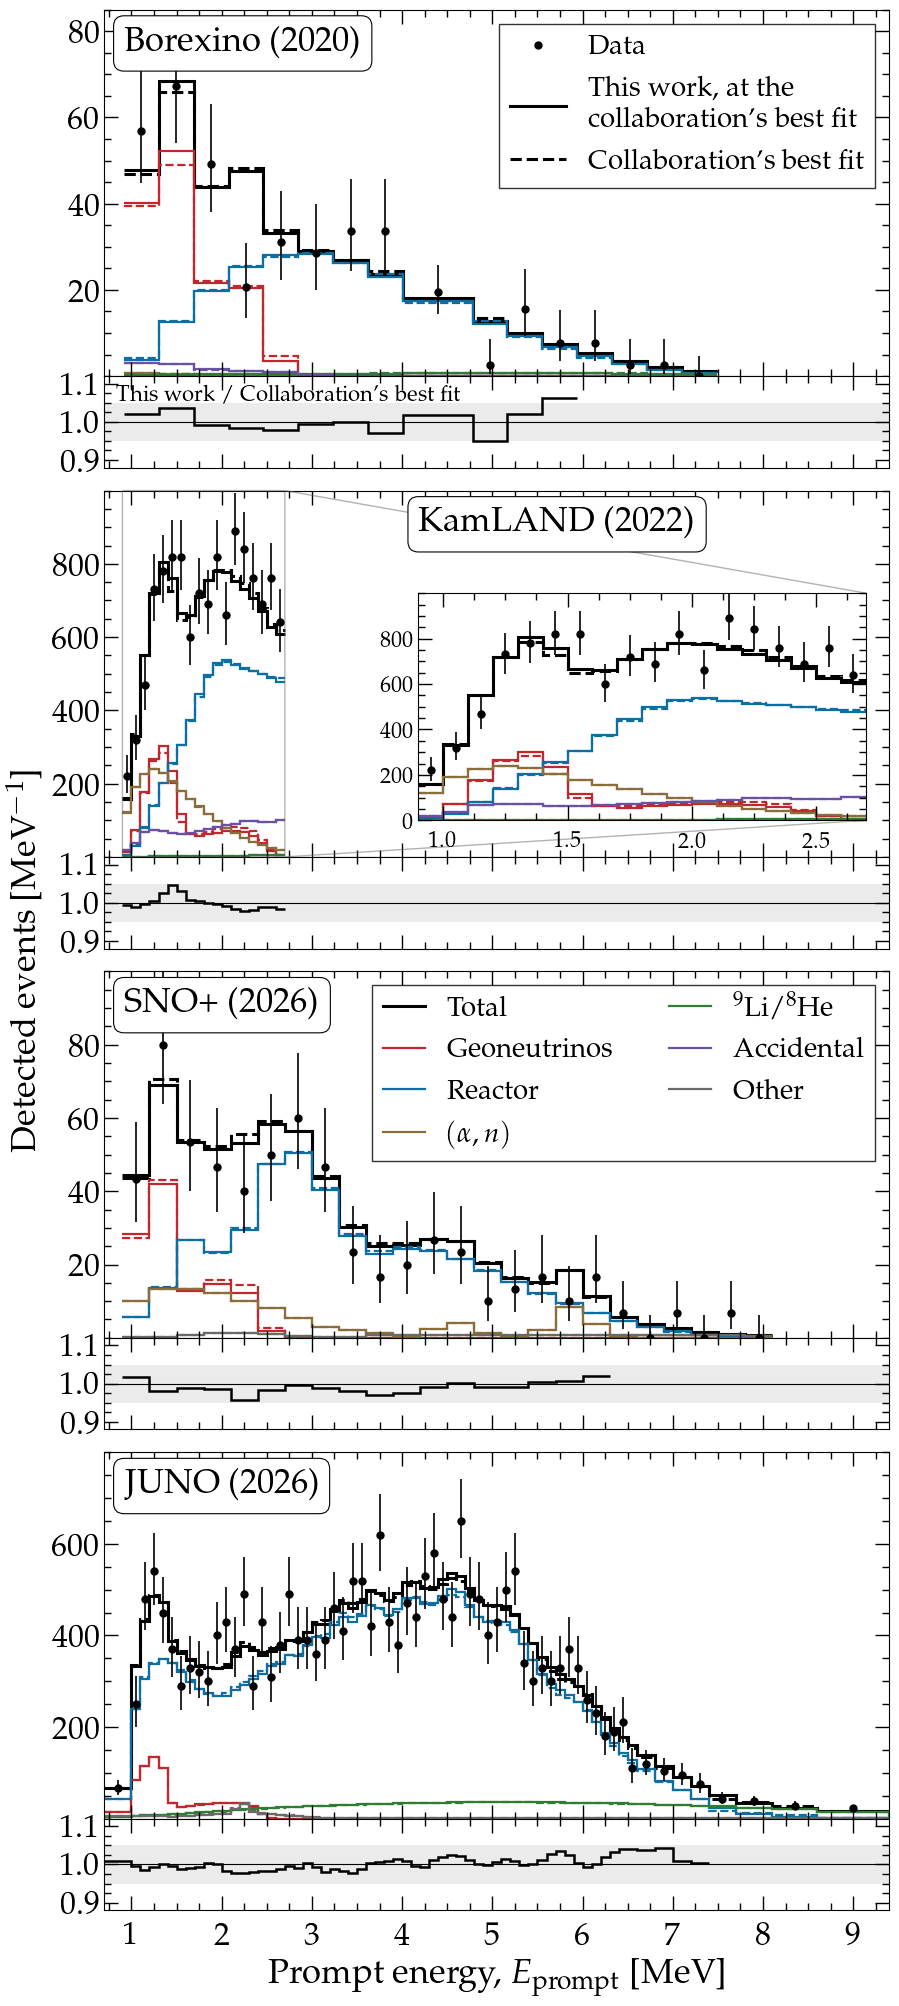

Borexino   12 of 16 bins shown: ours over theirs, mean |ratio - 1| = 0.0243, from 0.951 to 1.062
KamLAND    18 of 18 bins shown: ours over theirs, mean |ratio - 1| = 0.0138, from 0.978 to 1.046
SNO+       18 of 24 bins shown: ours over theirs, mean |ratio - 1| = 0.0148, from 0.957 to 1.020
JUNO       61 of 66 bins shown: ours over theirs, mean |ratio - 1| = 0.0134, from 0.977 to 1.042


In [13]:
figdata = data.use("reproduction")
rep = {site: figdata.reproduction(site) for site in figdata.SITES}
#: The share of its peak below which a collaboration's curve is too small to divide by.
RATIO_FLOOR = 0.10


def draw_reproduction(ax, r):
    """One experiment's data, and each component as we compute it and as its collaboration fitted it."""
    edges = r["edges"]
    width = np.diff(edges)
    centres = 0.5 * (edges[:-1] + edges[1:])
    for name in ("total",) + tuple(figdata.COMPONENTS):
        if name not in r["ours"]:
            continue
        color = "k" if name == "total" else COMPONENT_COLORS[name]
        lw = 2.2 if name == "total" else 1.6
        ax.stairs(r["theirs"][name] / width, edges, color=color, ls="--", lw=lw, baseline=None)
        ax.stairs(r["ours"][name] / width, edges, color=color, ls="-", lw=lw, baseline=None)
    low, high = helpers.poisson_interval(r["data"])
    ax.errorbar(centres, r["data"] / width, yerr=[low / width, high / width], fmt="o", ms=5, color="k",
                lw=1.2, capsize=0, zorder=5)


fig = plt.figure(figsize=(10.0, 23.0))
outer = fig.add_gridspec(4, 1, hspace=0.05)
axes = []
for k, site in enumerate(figdata.SITES):
    inner = outer[k].subgridspec(2, 1, height_ratios=[4, 1], hspace=0.0)
    ax = fig.add_subplot(inner[0], sharex=axes[0][0] if axes else None)
    res = fig.add_subplot(inner[1], sharex=ax)
    axes.append((ax, res))
    r = rep[site]
    draw_reproduction(ax, r)
    ax.set_ylim(0.0, Y_TOP[site])
    # No label at zero: the ratio strip's labels sit right below it.
    ax.set_yticks([t for t in Y_TICKS[site] if t > 0])
    minor_ticks(ax, x=False)
    # KamLAND's data reach the top of the common range's left end, so its label sits right of them.
    tag(ax, ANALYSES[site], x=0.40 if site == "kamland" else 0.025)
    plt.setp(ax.get_xticklabels(), visible=False)
    if site == "kamland":
        inset = ax.inset_axes([0.40, 0.10, 0.57, 0.62])
        draw_reproduction(inset, r)
        inset.set_xlim(r["edges"][0], r["edges"][-1])
        inset.set_ylim(0.0, Y_TOP[site])
        inset.set_yticks(Y_TICKS[site])
        inset.tick_params(labelsize=16)
        minor_ticks(inset)
        ax.indicate_inset_zoom(inset, edgecolor="0.4")
    # The ratio where the collaboration's fit holds at least 10% of its peak, per MeV: below that
    # the curves digitized from the papers' figures carry a few events per bin.
    edges, width = r["edges"], np.diff(r["edges"])
    shown = r["theirs"]["total"] / width >= RATIO_FLOOR * np.max(r["theirs"]["total"] / width)
    first, last = np.flatnonzero(shown)[[0, -1]]
    res.axhspan(0.95, 1.05, color="k", alpha=0.08, lw=0)
    res.axhline(1.0, color="k", lw=0.8)
    res.stairs((r["ours"]["total"] / r["theirs"]["total"])[first:last + 1], edges[first:last + 2], baseline=None,
               color="k", lw=1.8)
    res.set_ylim(0.88, 1.12)
    res.set_yticks((0.9, 1.0, 1.1))
    res.yaxis.set_minor_locator(MultipleLocator(0.025))
    if k == 0:
        res.text(0.015, 0.9, "This work / Collaboration's best fit", transform=res.transAxes, ha="left", va="top",
                 fontsize=16)
    if k < 3:
        plt.setp(res.get_xticklabels(), visible=False)
styles = [Line2D([], [], color="k", marker="o", ms=5, ls="none"), Line2D([], [], color="k", lw=2.2),
          Line2D([], [], color="k", lw=2.2, ls="--")]
# Ours is not a fit: it is our spectrum at the normalizations the collaboration's fit gives.
# The second entry on two lines, so that the box fits beside the data at the legends' size.
axes[0][0].legend(styles, ["Data", "This work, at the\ncollaboration's best fit", "Collaboration's best fit"],
                  loc="upper right", fontsize=LEGEND_SIZE,
                  frameon=True, edgecolor="k", fancybox=False)
parts = [Line2D([], [], color="k", lw=2.2)] + [Line2D([], [], color=COMPONENT_COLORS[c], lw=1.6)
                                               for c in figdata.COMPONENTS]
# Shorter lines than the default, so that the box clears SNO+'s label and data at the legends' size.
axes[2][0].legend(parts, ["Total"] + list(figdata.COMPONENTS.values()), loc="upper right", ncol=2,
                  fontsize=LEGEND_SIZE, handlelength=1.5, frameon=True, edgecolor="k", fancybox=False)
axes[-1][1].set_xlim(*X_RANGE)
energy_ticks(axes[-1][1])
axes[-1][1].set_xlabel(r"Prompt energy, $E_{\rm prompt}$ [MeV]")
stack_ylabel([a for pair in axes for a in pair], EVENTS_LABEL, on=axes[1][0])
save(fig, "reproduction")
plt.show()

for site, name in figdata.SITES.items():
    r = rep[site]
    width = np.diff(r["edges"])
    ratio = r["ours"]["total"] / r["theirs"]["total"]
    shown = r["theirs"]["total"] / width >= RATIO_FLOOR * np.max(r["theirs"]["total"] / width)
    print(f"{name:9s} {shown.sum():3d} of {shown.size} bins shown: ours over theirs, mean |ratio - 1| = "
          f"{np.mean(np.abs(ratio[shown] - 1)):.4f}, from {ratio[shown].min():.3f} to {ratio[shown].max():.3f}")

## Figure B.2

Response function of each data set.

Data: `data/detector_response.json`.

wrote figures/detector_response.pdf


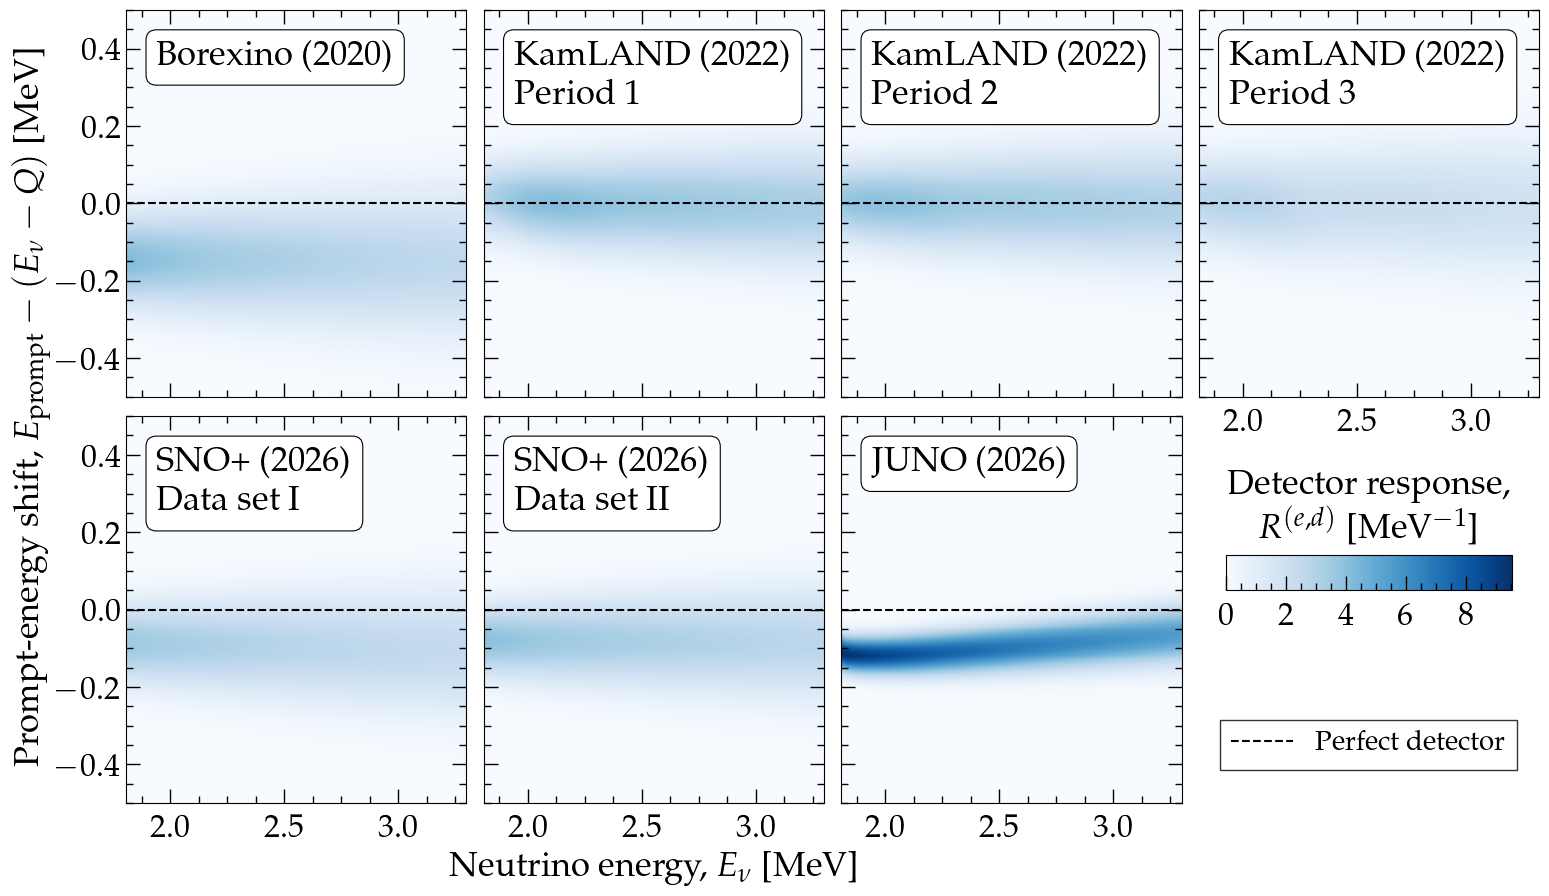

In [14]:
figdata = data.use("detector_response")
from plotting.coverage import corner_label

sets = figdata.response_data_sets()
maps = [figdata.detector_response(det, flat) for _, det, flat in sets]
#: One colour scale for every panel, up to the largest response of any.
R_MAX = max(m.max() for m in maps)

fig, axes = plt.subplots(2, 4, figsize=(18.0, 9.6), sharex=True, sharey=True,
                         gridspec_kw={"hspace": 0.05, "wspace": 0.05})
for ax, (label, _, _), m in zip(axes.flat, sets, maps):
    image = ax.pcolormesh(figdata.RESPONSE_E_NU, figdata.RESPONSE_SHIFT, m, cmap="Blues", vmin=0.0, vmax=R_MAX,
                          shading="nearest", rasterized=True)
    ax.axhline(0.0, color="k", lw=1.5, ls="--")
    corner_label(ax, label, LABEL_SIZE)
    ax.set_xlim(figdata.RESPONSE_E_NU[0], figdata.RESPONSE_E_NU[-1])
    ax.set_ylim(figdata.RESPONSE_SHIFT[0], figdata.RESPONSE_SHIFT[-1])
    ax.xaxis.set_major_locator(MultipleLocator(0.5))
    ax.yaxis.set_major_locator(MultipleLocator(0.2))
    minor_ticks(ax)
# The top right panel has none below it, so it shows its own energies.
axes[0, 3].tick_params(labelbottom=True)
# The eighth slot holds the colour scale and the key to the dashed line.
key = axes[1, 3]
key.axis("off")
cax = key.inset_axes([0.08, 0.55, 0.84, 0.09])
bar = fig.colorbar(image, cax=cax, orientation="horizontal")
bar.set_label("Detector response,\n" + r"$R^{(e,d)}$ [MeV$^{-1}$]", fontsize=LABEL_SIZE, labelpad=12)
cax.xaxis.set_label_position("top")
bar.set_ticks([0, 2, 4, 6, 8])
bar.ax.xaxis.set_minor_locator(AutoMinorLocator(4))
key.legend(handles=[Line2D([], [], color="k", lw=1.5, ls="--", label="Perfect detector")], loc="lower center",
           bbox_to_anchor=(0.5, 0.05), fontsize=LEGEND_SIZE, handlelength=2.2,
           frameon=True, edgecolor="k", fancybox=False)
stack_ylabel(list(axes[:, 0]), r"Prompt-energy shift, $E_{\rm prompt} - (E_\nu - Q)$ [MeV]")
axes[1, 1].set_xlabel(r"Neutrino energy, $E_\nu$ [MeV]")
save(fig, "detector_response")
plt.show()

## Figure B.3

Reactor antineutrinos in each data set, reactor by reactor, with and without decay.

Data: `data/reactor_spectra.json`.

wrote figures/reactor_spectra.pdf


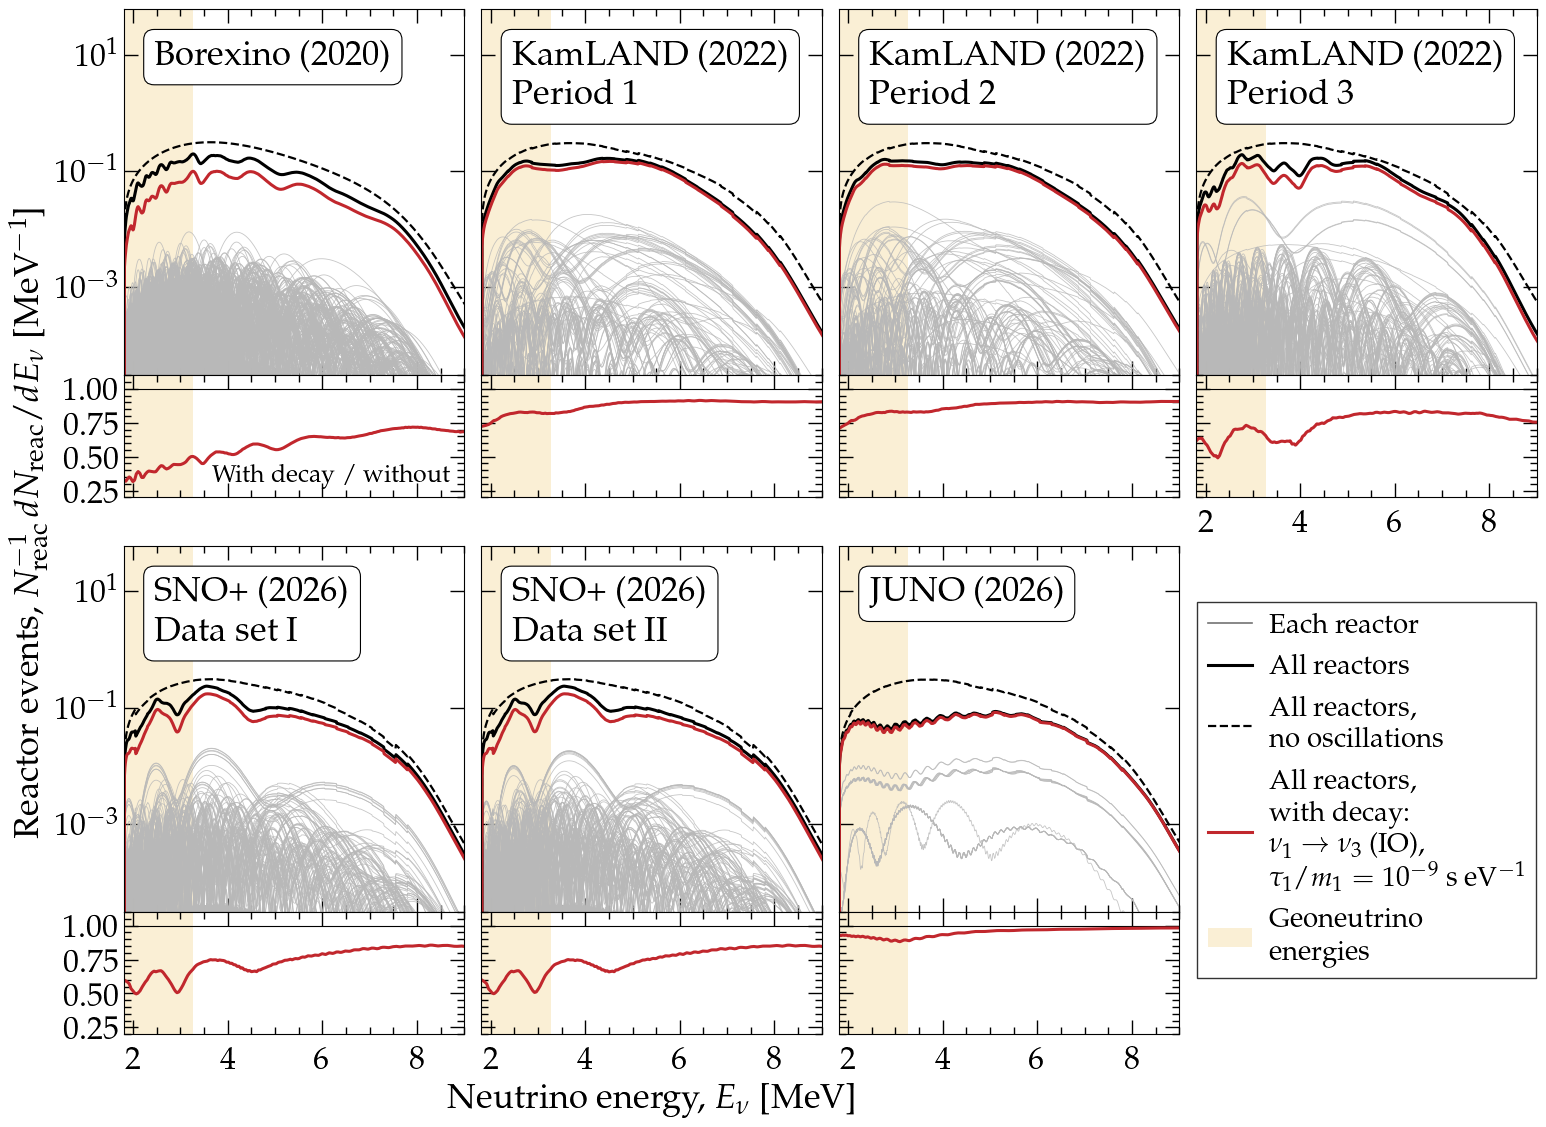

Borexino (2020)               645 cores; 0.549 survive oscillations, 0.265 of them below 3.27 MeV; decay removes 0.469, at 2, 3, 6 MeV 0.682, 0.558, 0.354
KamLAND (2022) Period 1        92 cores; 0.580 survive oscillations, 0.252 of them below 3.27 MeV; decay removes 0.132, at 2, 3, 6 MeV 0.253, 0.175, 0.088
KamLAND (2022) Period 2        96 cores; 0.560 survive oscillations, 0.275 of them below 3.27 MeV; decay removes 0.141, at 2, 3, 6 MeV 0.252, 0.167, 0.096
KamLAND (2022) Period 3        99 cores; 0.574 survive oscillations, 0.273 of them below 3.27 MeV; decay removes 0.268, at 2, 3, 6 MeV 0.405, 0.288, 0.166
SNO+ (2026) Data set I        380 cores; 0.547 survive oscillations, 0.235 of them below 3.27 MeV; decay removes 0.290, at 2, 3, 6 MeV 0.483, 0.471, 0.207
SNO+ (2026) Data set II       381 cores; 0.547 survive oscillations, 0.235 of them below 3.27 MeV; decay removes 0.290, at 2, 3, 6 MeV 0.483, 0.472, 0.207
JUNO (2026)                    15 cores; 0.328 survive oscillations, 0

In [15]:
figdata = data.use("reactor_spectra")
from matplotlib.patches import Patch
from plotting.coverage import corner_label

rs = figdata.reactor_spectra(tau1_over_m1=10.0 ** TAU)
e = rs["energy"]
#: The end of the geoneutrino spectrum, the main branch of 214Bi, MeV.
GEO_END_MEV = 3.27
#: The shade of each reactor's line; the legend's sample is darker, so that it shows.
REACTOR_GRAY = "0.72"

fig = plt.figure(figsize=(18.0, 12.4))
outer = fig.add_gridspec(2, 4, hspace=0.10, wspace=0.05)
mains, strips = [], []
for k, d in enumerate(rs["data_sets"]):
    inner = outer[k // 4, k % 4].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.0)
    ax = fig.add_subplot(inner[0], sharex=mains[0] if mains else None, sharey=mains[0] if mains else None)
    strip = fig.add_subplot(inner[1], sharex=ax, sharey=strips[0] if strips else None)
    mains.append(ax)
    strips.append(strip)
    for a in (ax, strip):
        a.axvspan(e[0], GEO_END_MEV, color="#e6a817", alpha=0.18, lw=0)
    # Stored as an image, at the file's full resolution: a thousand lines as vectors made a 5 MB file.
    for part in d["reactors"]:
        ax.plot(e, part, color=REACTOR_GRAY, lw=0.6, alpha=0.8, rasterized=True)
    ax.plot(e, d["unoscillated"], color="k", lw=1.6, ls="--")
    ax.plot(e, d["total"], color="k", lw=2.2)
    ax.plot(e, d["decayed"], color=COLORS[TAU], lw=2.2)
    alive = d["total"] > 0
    strip.axhline(1.0, color="k", lw=0.8)
    strip.plot(e[alive], d["decayed"][alive] / d["total"][alive], color=COLORS[TAU], lw=2.2)
    ax.set_yscale("log")
    # The top leaves room for the labels above every curve.
    ax.set_ylim(3e-5, 60.0)
    ax.set_xlim(1.8, 9.0)
    strip.set_ylim(0.2, 1.1)
    strip.yaxis.set_major_locator(MultipleLocator(0.25))
    strip.yaxis.set_minor_locator(AutoMinorLocator(5))
    ax.xaxis.set_major_locator(MultipleLocator(2.0))
    ax.xaxis.set_minor_locator(AutoMinorLocator(4))
    plt.setp(ax.get_xticklabels(), visible=False)
    if k % 4:
        plt.setp(ax.get_yticklabels() + strip.get_yticklabels(), visible=False)
    # Only the bottom row, and the top right panel, which has none below it, show their energies.
    if k < 3:
        plt.setp(strip.get_xticklabels(), visible=False)
    corner_label(ax, d["label"], LABEL_SIZE)
strips[0].text(0.96, 0.07, "With decay / without", transform=strips[0].transAxes, fontsize=18,
               ha="right", va="bottom")
key = fig.add_subplot(outer[1, 3])
key.axis("off")
key.legend(handles=[Line2D([], [], color="0.45", lw=1.2, label="Each reactor"),
                    Line2D([], [], color="k", lw=2.2, label="All reactors"),
                    Line2D([], [], color="k", lw=1.6, ls="--", label="All reactors,\nno oscillations"),
                    Line2D([], [], color=COLORS[TAU], lw=2.2,
                           label="All reactors,\nwith decay:\n" + CHANNEL + ",\n" + tau_label(TAU)),
                    Patch(color="#e6a817", alpha=0.18, lw=0, label="Geoneutrino\nenergies")],
           loc="center", fontsize=LEGEND_SIZE, handlelength=1.6, handletextpad=0.6,
           frameon=True, edgecolor="k", fancybox=False)
# One label for the whole height, panels and strips together.
stack_ylabel([mains[0], mains[4], strips[4]], r"Reactor events, $N_{\rm reac}^{-1}\, dN_{\rm reac}/dE_\nu$ [MeV$^{-1}$]",
             on=mains[4])
strips[5].set_xlabel(r"Neutrino energy, $E_\nu$ [MeV]")
save(fig, "reactor_spectra")
plt.show()

below = e < GEO_END_MEV
for d in rs["data_sets"]:
    ratio = np.interp((2.0, 3.0, 6.0), e[d["total"] > 0], (d["decayed"] / np.where(d["total"] > 0, d["total"], 1))[d["total"] > 0])
    print(f"{d['label'].replace(chr(10), ' '):28s} {len(d['reactors']):4d} cores; "
          f"{np.trapz(d['total'], e):.3f} survive oscillations, {np.trapz(d['total'][below], e[below]) / np.trapz(d['total'], e):.3f} "
          f"of them below {GEO_END_MEV} MeV; decay removes {1 - np.trapz(d['decayed'], e) / np.trapz(d['total'], e):.3f}, "
          f"at 2, 3, 6 MeV {1 - ratio[0]:.3f}, {1 - ratio[1]:.3f}, {1 - ratio[2]:.3f}")

## Figure B.4

How far reactor antineutrinos and geoneutrinos travel to each data set.

Data: `data/reactor_flux_by_distance.json`.

wrote figures/reactor_flux_by_distance.pdf


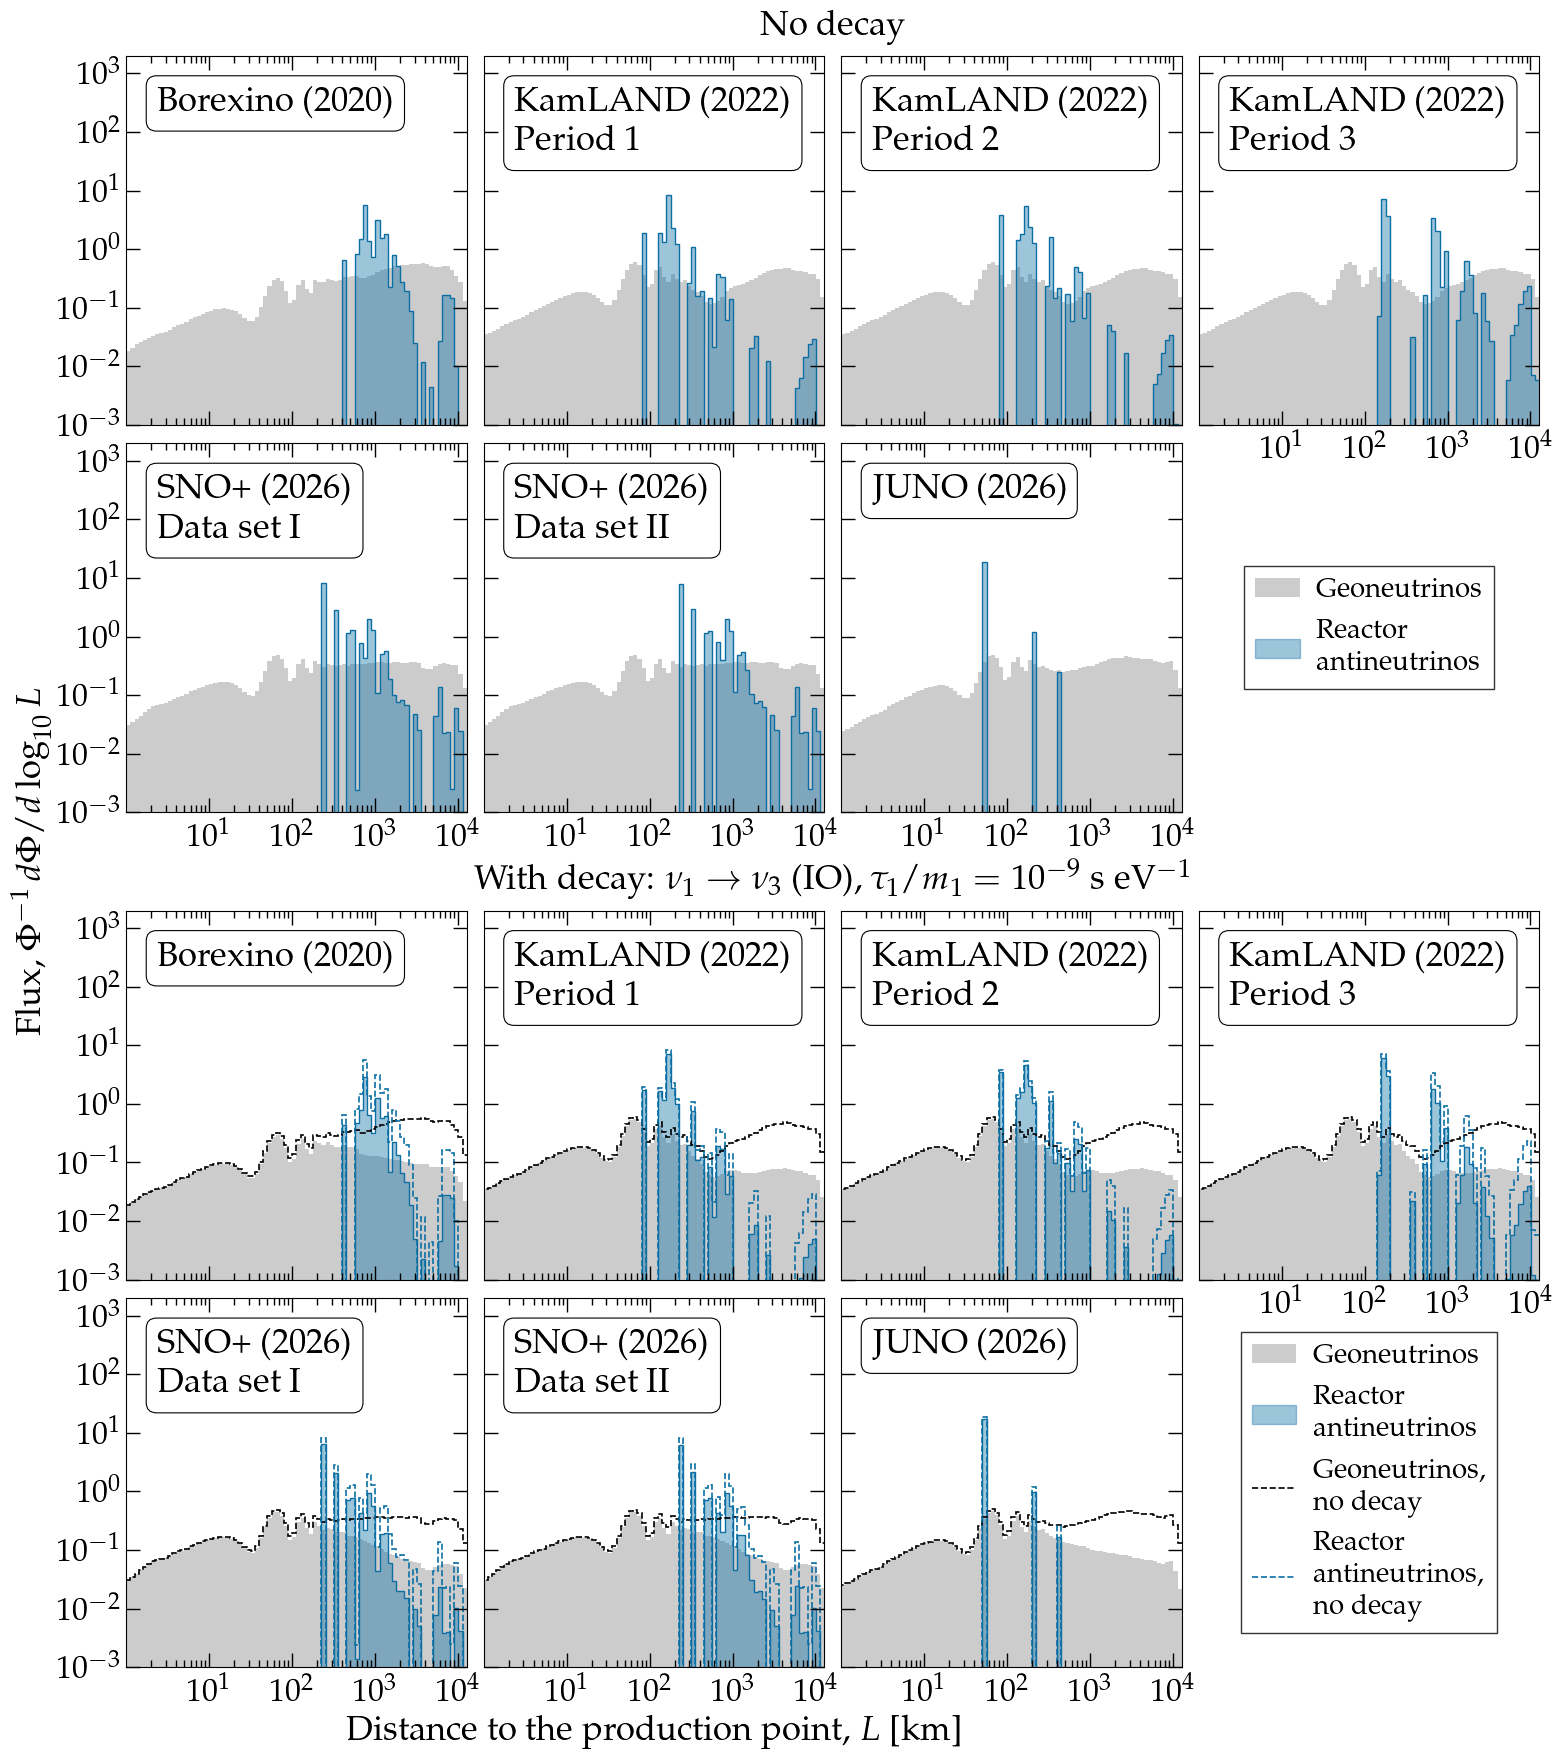

Borexino (2020)              typical distance   1000 km, 0.000 within 100 km, 0.460 beyond 1000 km; decay keeps 0.434 of the reactor flux and 0.459 of the geoneutrinos
KamLAND (2022) Period 1      typical distance    185 km, 0.096 within 100 km, 0.007 beyond 1000 km; decay keeps 0.816 of the reactor flux and 0.582 of the geoneutrinos
KamLAND (2022) Period 2      typical distance    183 km, 0.188 within 100 km, 0.010 beyond 1000 km; decay keeps 0.812 of the reactor flux and 0.582 of the geoneutrinos
KamLAND (2022) Period 3      typical distance    389 km, 0.000 within 100 km, 0.111 beyond 1000 km; decay keeps 0.656 of the reactor flux and 0.582 of the geoneutrinos
SNO+ (2026) Data set I       typical distance    450 km, 0.000 within 100 km, 0.105 beyond 1000 km; decay keeps 0.634 of the reactor flux and 0.578 of the geoneutrinos
SNO+ (2026) Data set II      typical distance    450 km, 0.000 within 100 km, 0.106 beyond 1000 km; decay keeps 0.634 of the reactor flux and 0.578 of the geone

In [16]:
figdata = data.use("reactor_flux_by_distance")
from matplotlib.ticker import LogLocator
from matplotlib.patches import Patch
from plotting.coverage import corner_label

rd = figdata.reactor_flux_by_distance(TAU)
edges = rd["edges"]
per_decade = np.diff(np.log10(edges))
#: Shades: the geoneutrinos as in no other figure, the reactor antineutrinos in the blue of the reactor elsewhere.
GEO_FILL, REACTOR_BLUE = "0.80", COMPONENT_COLORS["reactor"]

fig = plt.figure(figsize=(18.0, 19.5))
outer = fig.add_gridspec(2, 1, hspace=0.13)
blocks = [outer[b].subgridspec(2, 4, hspace=0.05, wspace=0.05) for b in (0, 1)]
axes = {}
for b in (0, 1):
    for k in range(8):
        first = axes.get((0, 0))
        axes[b, k] = fig.add_subplot(blocks[b][k // 4, k % 4], sharex=first, sharey=first)
for b in (0, 1):
    for k, d in enumerate(rd["data_sets"]):
        ax = axes[b, k]
        g_nd, g_dc = rd["geo"][d["site"]]
        G, R = g_nd.sum(), d["no_decay"].sum()
        g, r = (g_nd, d["no_decay"]) if b == 0 else (g_dc, d["decay"])
        ax.stairs(g / per_decade / G, edges, baseline=1e-9, fill=True, color=GEO_FILL, lw=0)
        ax.stairs(r / per_decade / R, edges, baseline=1e-9, fill=True, color=REACTOR_BLUE, alpha=0.40, lw=0)
        ax.stairs(r / per_decade / R, edges, color=REACTOR_BLUE, lw=1.0, baseline=None)
        if b == 1:
            ax.stairs(g_nd / per_decade / G, edges, color="k", lw=1.2, ls="--", baseline=None)
            ax.stairs(d["no_decay"] / per_decade / R, edges, color=REACTOR_BLUE, lw=1.2, ls="--", baseline=None)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlim(1.0, edges[-1])
        # The top leaves room for the two-line labels above every bin.
        ax.set_ylim(1e-3, 2000.0)
        # Labels from 10 km: one at 1 km would meet the 10^4 of the panel to its left.
        ax.set_xticks([1e1, 1e2, 1e3, 1e4])
        ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10), numticks=20))
        ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=10))
        if k % 4:
            plt.setp(ax.get_yticklabels(), visible=False)
        if k < 3:
            plt.setp(ax.get_xticklabels(), visible=False)
        corner_label(ax, d["label"], LABEL_SIZE)
    # The eighth slot of each block holds its key.
    key = axes[b, 7]
    key.axis("off")
    handles = [Patch(color=GEO_FILL, lw=0, label="Geoneutrinos"),
               Patch(facecolor=REACTOR_BLUE, alpha=0.40, edgecolor=REACTOR_BLUE, lw=1.0, label="Reactor\nantineutrinos")]
    if b == 1:
        handles += [Line2D([], [], color="k", lw=1.2, ls="--", label="Geoneutrinos,\nno decay"),
                    Line2D([], [], color=REACTOR_BLUE, lw=1.2, ls="--", label="Reactor\nantineutrinos,\nno decay")]
    key.legend(handles=handles, loc="center", fontsize=LEGEND_SIZE, handlelength=1.6, handletextpad=0.6,
               frameon=True, edgecolor="k", fancybox=False)
# Each block says what it shows.
for b, title in ((0, "No decay"), (1, "With decay: " + CHANNEL + ", " + tau_label(TAU))):
    left, right = axes[b, 0].get_position().x0, axes[b, 3].get_position().x1
    fig.text(0.5 * (left + right), axes[b, 0].get_position().y1 + 0.006, title, ha="center", va="bottom",
             fontsize=LABEL_SIZE)
axes[1, 5].set_xlabel(r"Distance to the production point, $L$ [km]")
stack_ylabel([axes[0, 0], axes[1, 4]], r"Flux, $\Phi^{-1}\, d\Phi/d\log_{10} L$", on=axes[1, 4])
save(fig, "reactor_flux_by_distance")
plt.show()

centres = np.sqrt(edges[:-1] * edges[1:])
for d in rd["data_sets"]:
    nd, dc = d["no_decay"], d["decay"]
    g_nd, g_dc = rd["geo"][d["site"]]
    print(f"{d['label'].replace(chr(10), ' '):28s} typical distance {10 ** (np.sum(nd * np.log10(centres)) / nd.sum()):6.0f} km, "
          f"{nd[edges[1:] <= 100].sum() / nd.sum():.3f} within 100 km, {nd[edges[:-1] >= 1000].sum() / nd.sum():.3f} beyond 1000 km; "
          f"decay keeps {dc.sum() / nd.sum():.3f} of the reactor flux and {g_dc.sum() / g_nd.sum():.3f} of the geoneutrinos")

## Figure C.1

Lower limits from data compared with those of simulated experiments without decay.

Data: `data/brazil.json`.

wrote figures/brazil.pdf


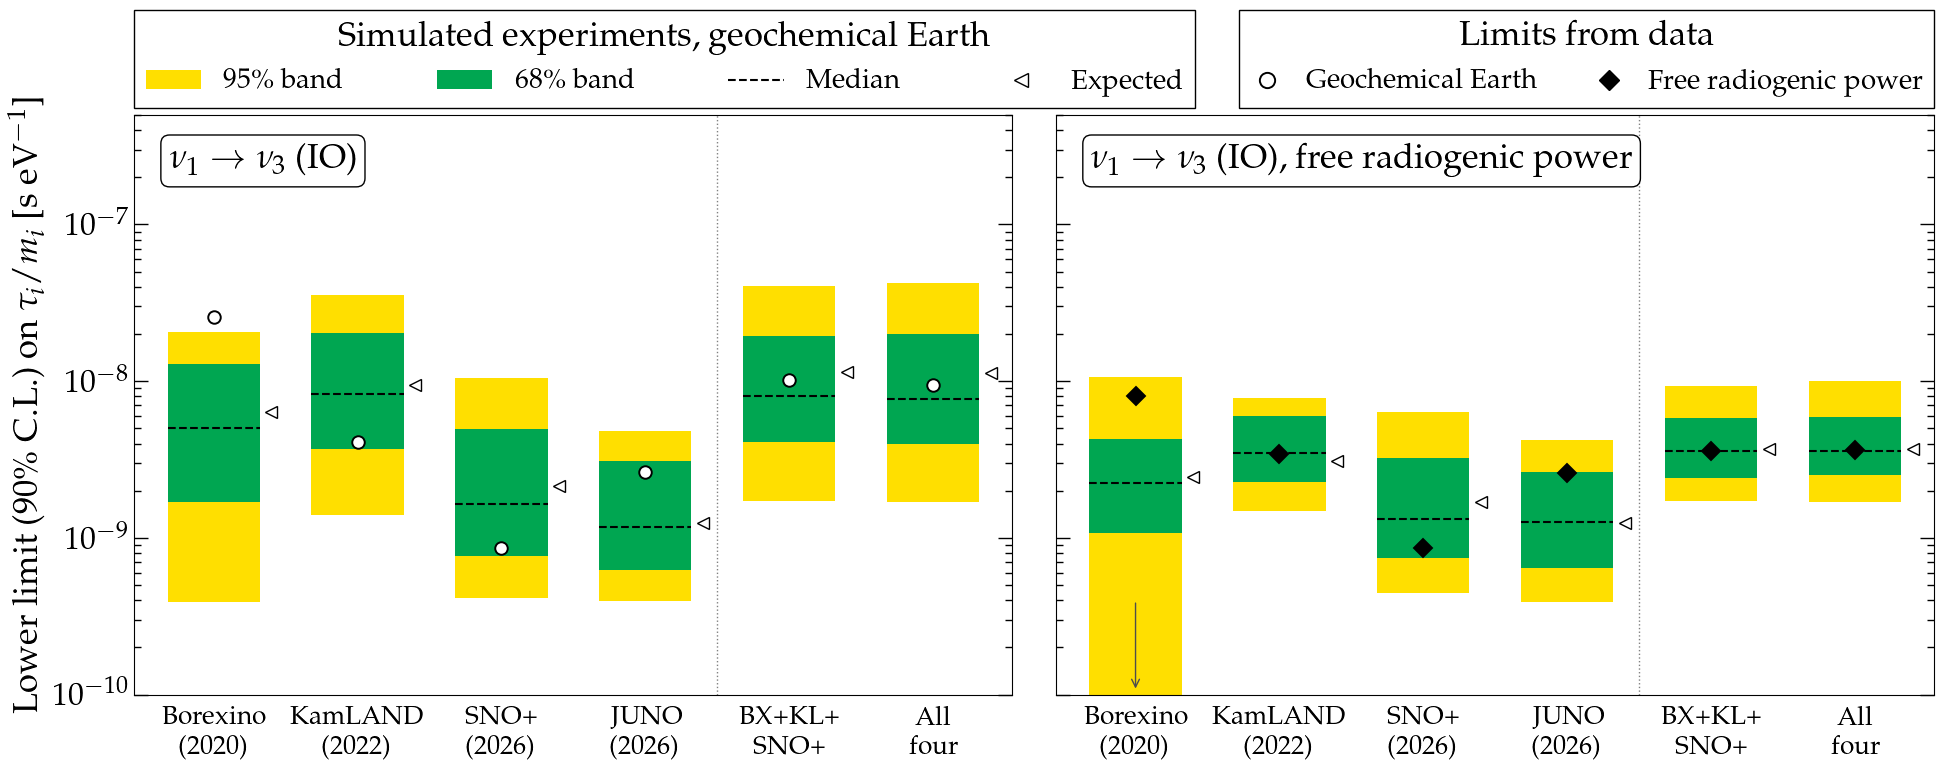

In [17]:
figdata = data.use("brazil")
from plotting import brazil as plot_brazil

fig = plot_brazil.figure_paper()
save(fig, "brazil")
plt.show()

## Figure D.1

Coverage of the 90% C.L. limits, tested with simulated experiments with decay.

Data: `data/coverage.json`.

wrote figures/coverage.pdf


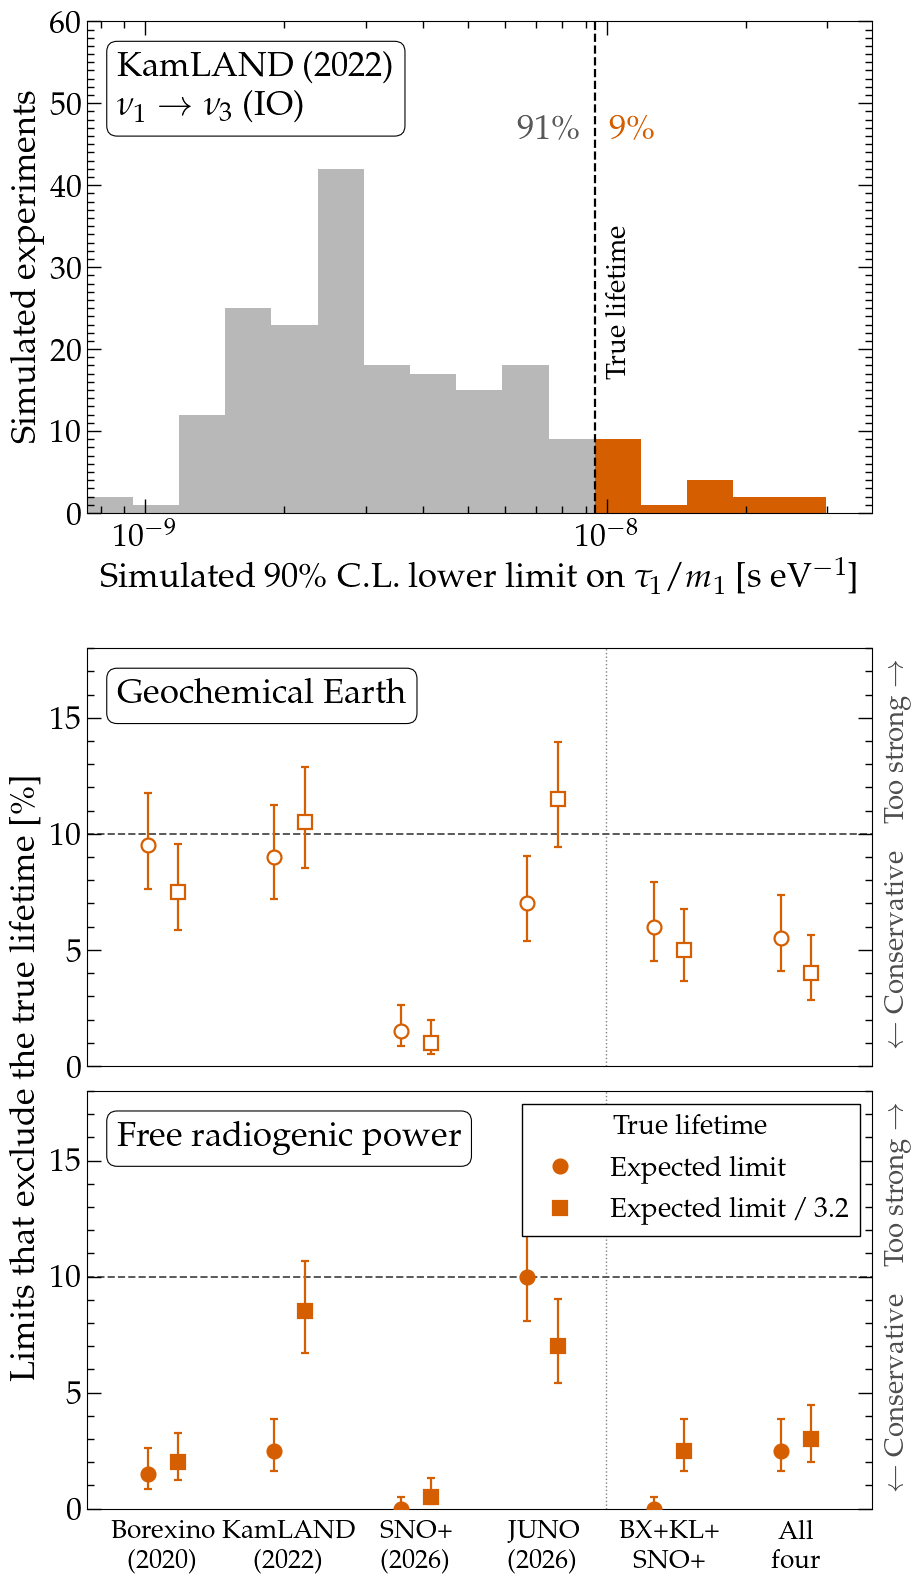

borexino, power assumed, at the expected limit: 19 of 200 exclude the true lifetime (9.5%)
borexino, power assumed, half a decade shorter: 15 of 200 exclude the true lifetime (7.5%)
borexino, power free, at the expected limit: 3 of 200 exclude the true lifetime (1.5%)
borexino, power free, half a decade shorter: 4 of 200 exclude the true lifetime (2.0%)
kamland, power assumed, at the expected limit: 18 of 200 exclude the true lifetime (9.0%)
kamland, power assumed, half a decade shorter: 21 of 200 exclude the true lifetime (10.5%)
kamland, power free, at the expected limit: 5 of 200 exclude the true lifetime (2.5%)
kamland, power free, half a decade shorter: 17 of 200 exclude the true lifetime (8.5%)
snoplus, power assumed, at the expected limit: 3 of 200 exclude the true lifetime (1.5%)
snoplus, power assumed, half a decade shorter: 2 of 200 exclude the true lifetime (1.0%)
snoplus, power free, at the expected limit: 0 of 200 exclude the true lifetime (0.0%)
snoplus, power free, half 

In [18]:
figdata = data.use("coverage")
from plotting import coverage as plot_coverage

fig = plot_coverage.figure_paper()
save(fig, "coverage")
plt.show()

for _, site, treatment, expected, excluded, n in plot_coverage.paper_points():
    if n < plot_coverage.PAPER_SIMULATED:
        continue                                        # a test still running, as the figure says
    print(f"{site}, power {'assumed' if treatment == 'assumed' else 'free'}, "
          f"{'at the expected limit' if expected else 'half a decade shorter'}: "
          f"{excluded} of {n} exclude the true lifetime ({100 * excluded / n:.1f}%)")

## Figure E.1

Fitted values of the parameters of the four experiments combined, with the radiogenic power free, and how much each moves the limit.

Data: `data/impacts.json`.

wrote figures/impacts.pdf


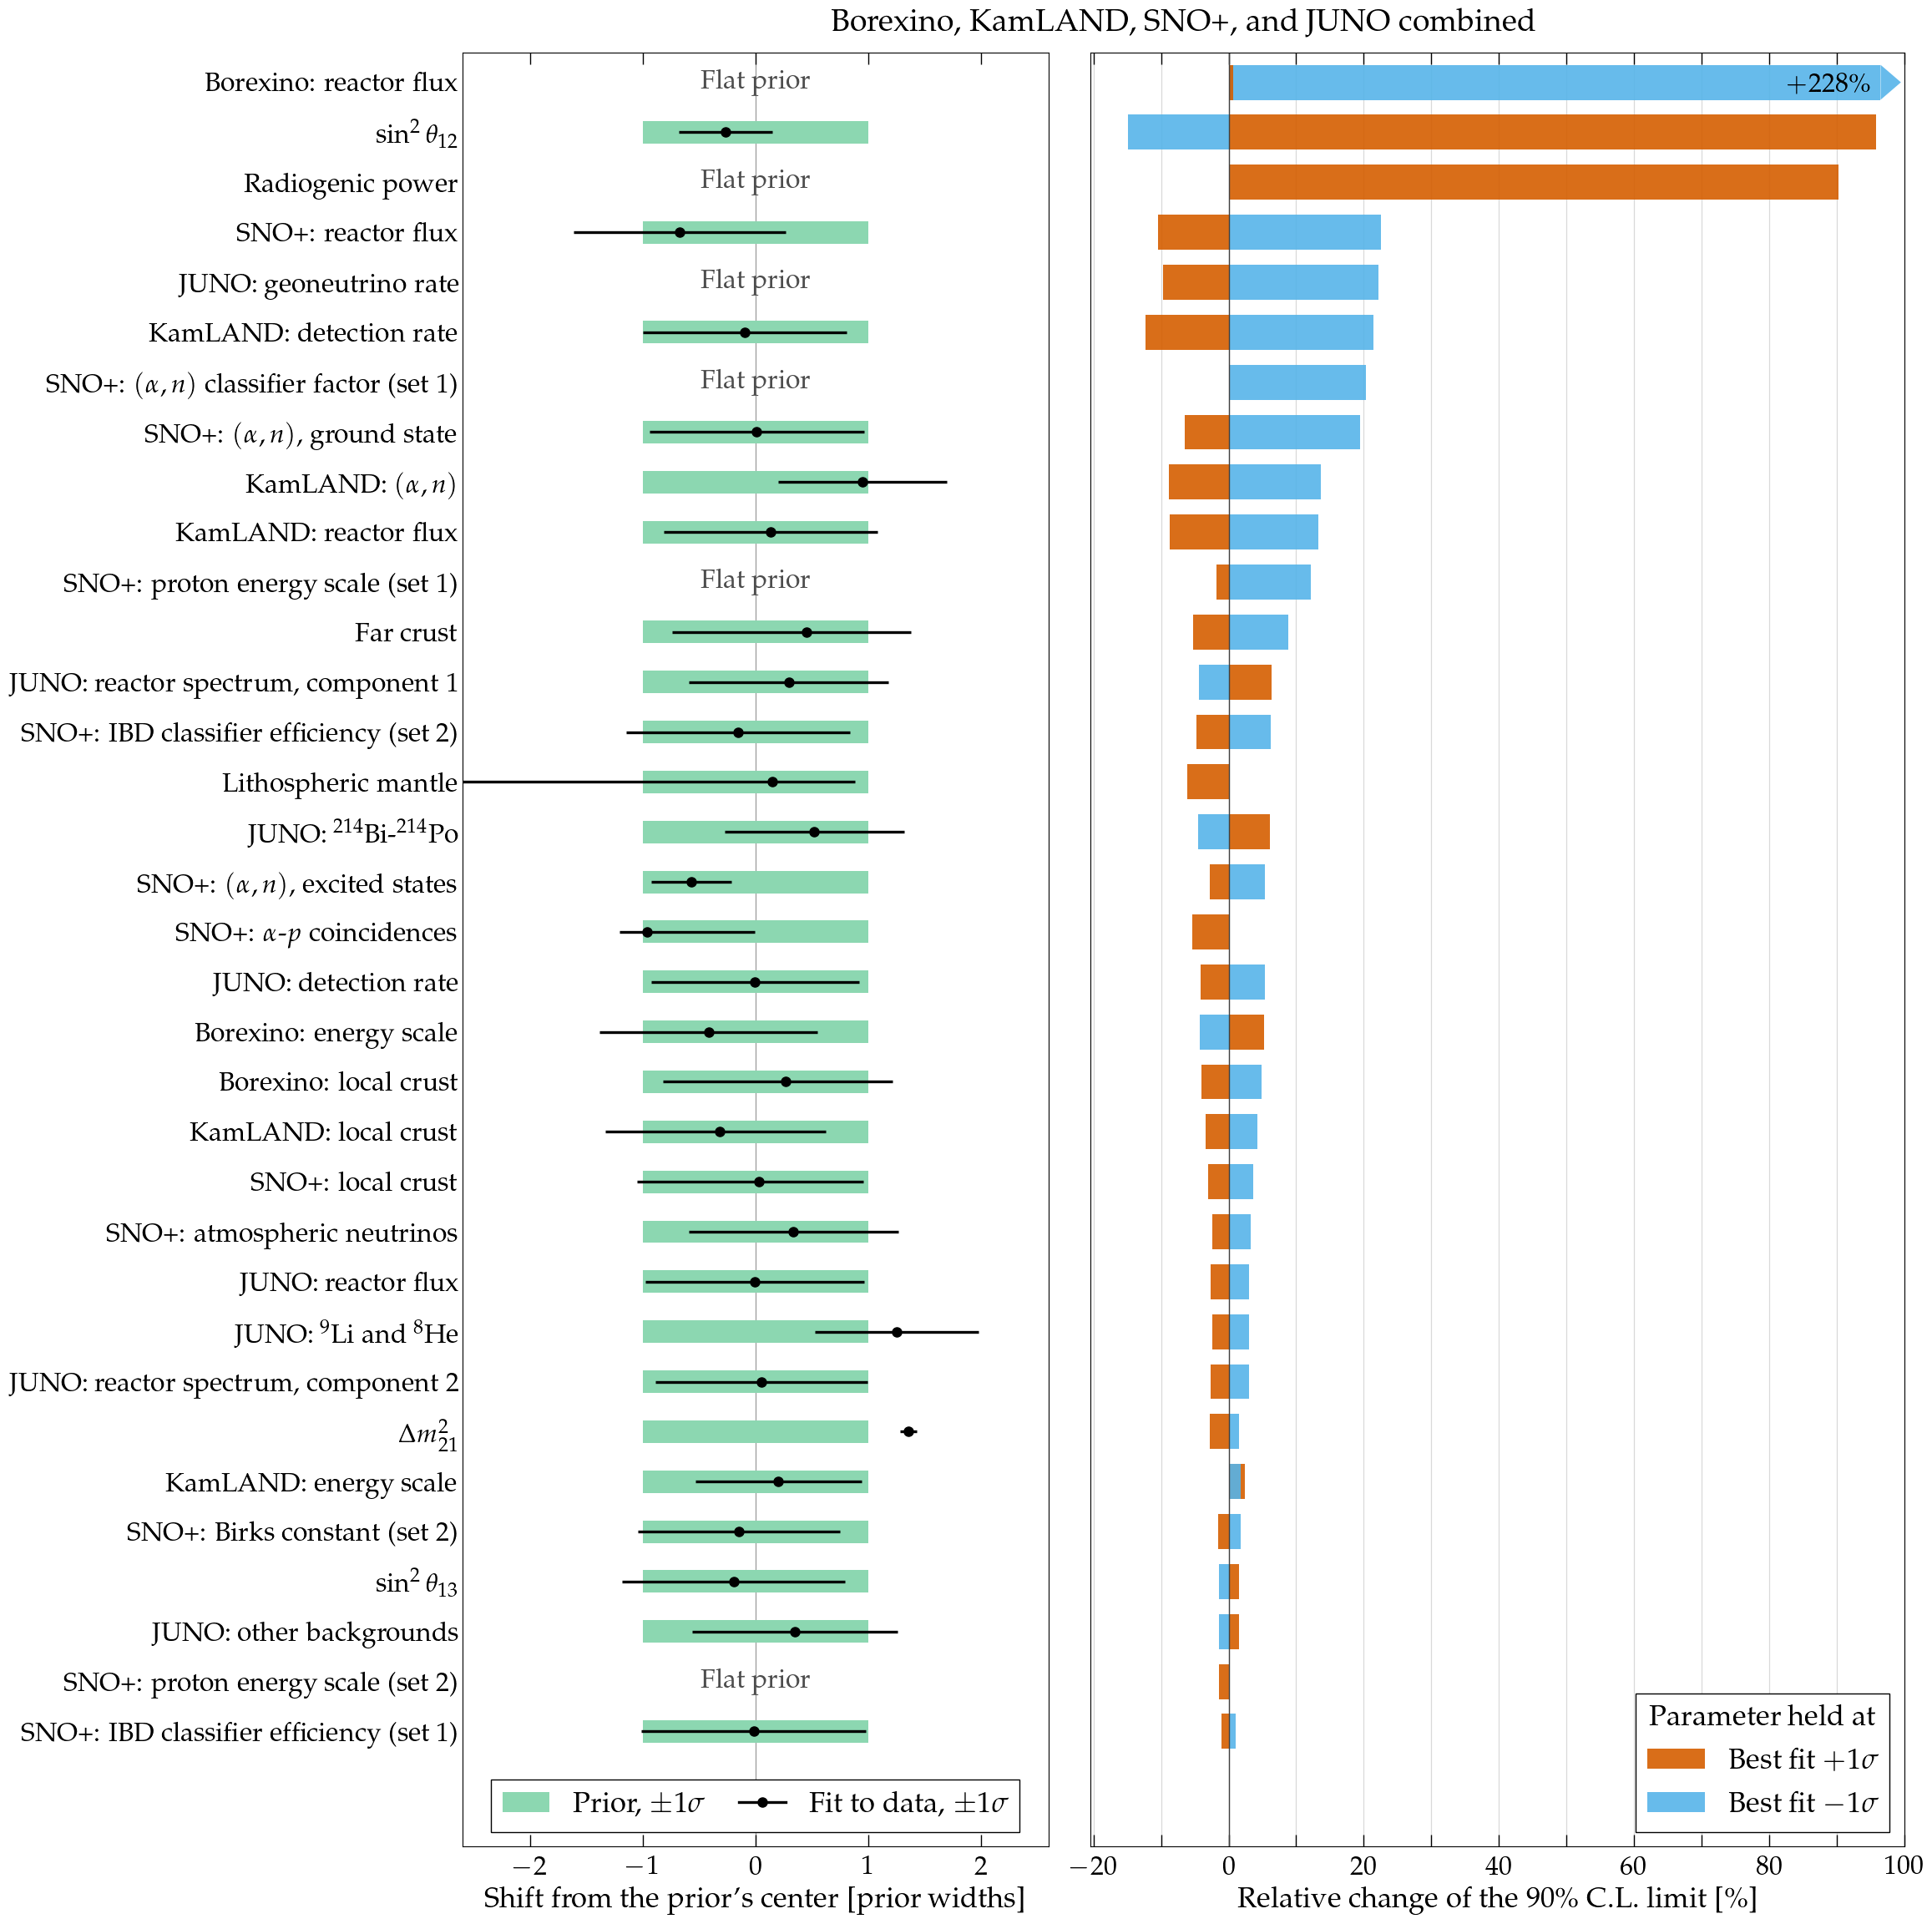

34 parameters shown, 39 left out (under 1%)
  norm_reactor@borexino: +1 sigma +1%, -1 sigma +228%
  sin2_th12: +1 sigma +96%, -1 sigma -15%
  bse_power_tw: +1 sigma +90%
  norm_reactor@snoplus: +1 sigma -10%, -1 sigma +23%
  norm_geo@juno: +1 sigma -10%, -1 sigma +22%
  delta_detector_rate@kamland: +1 sigma -12%, -1 sigma +21%


In [19]:
figdata = data.use("impacts")
from plotting import impacts as plot_impacts

# All four's impacts are those of the fit with the radiogenic power free, the paper's leading limit. The
# impact axis stops at 100%: Borexino's reactor flux, beyond it, ends in a triangle with its value
# (plot_impacts.CUT_ALL).
plot_impacts.ss.use_treatment("profiled")
fig = plot_impacts.figure_combined_all()
save(fig, "impacts")
plt.show()

rows, left_out = plot_impacts.shown("combined_all")
print(f"{len(rows)} parameters shown, {left_out} left out (under 1%)")
for name, change in rows[:6]:
    print(f"  {name}: " + ", ".join(f"{side} sigma {100 * v:+.0f}%" for side, v in sorted(change.items())))
# The other impact figures (Figs. E.2 and E.3) have records with the power assumed only: back to the default.
plot_impacts.ss.use_treatment("assumed")

## Figure E.2 and E.3

How much each parameter moves the limits of each experiment, and of Borexino, KamLAND, and SNO+ combined.

Data: `data/impacts_experiments.json`.

wrote figures/impacts_experiments.pdf


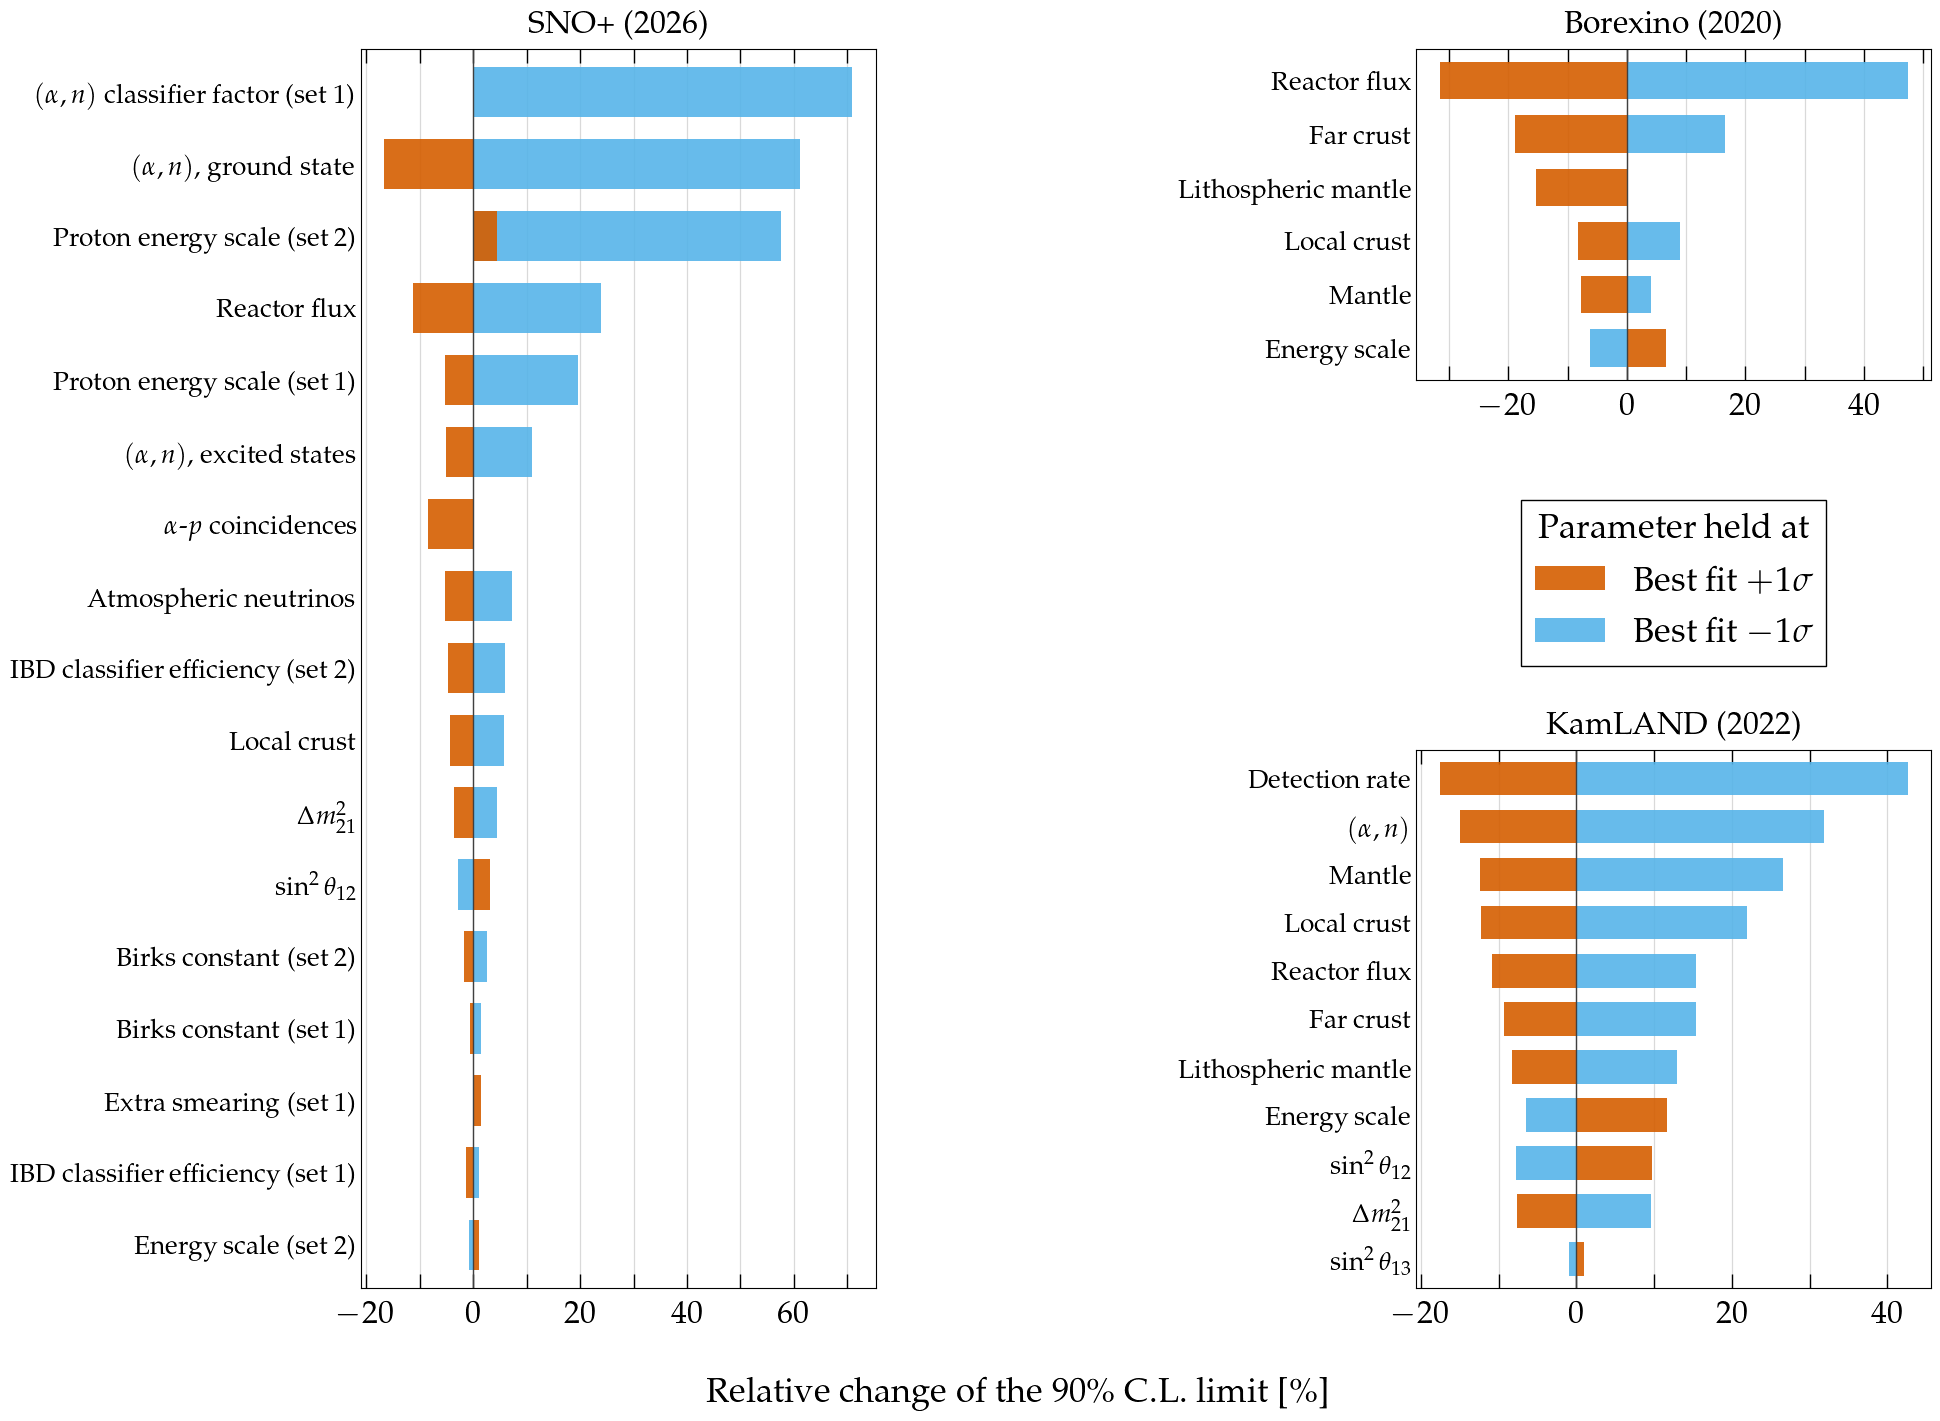

wrote figures/impacts_juno_three.pdf


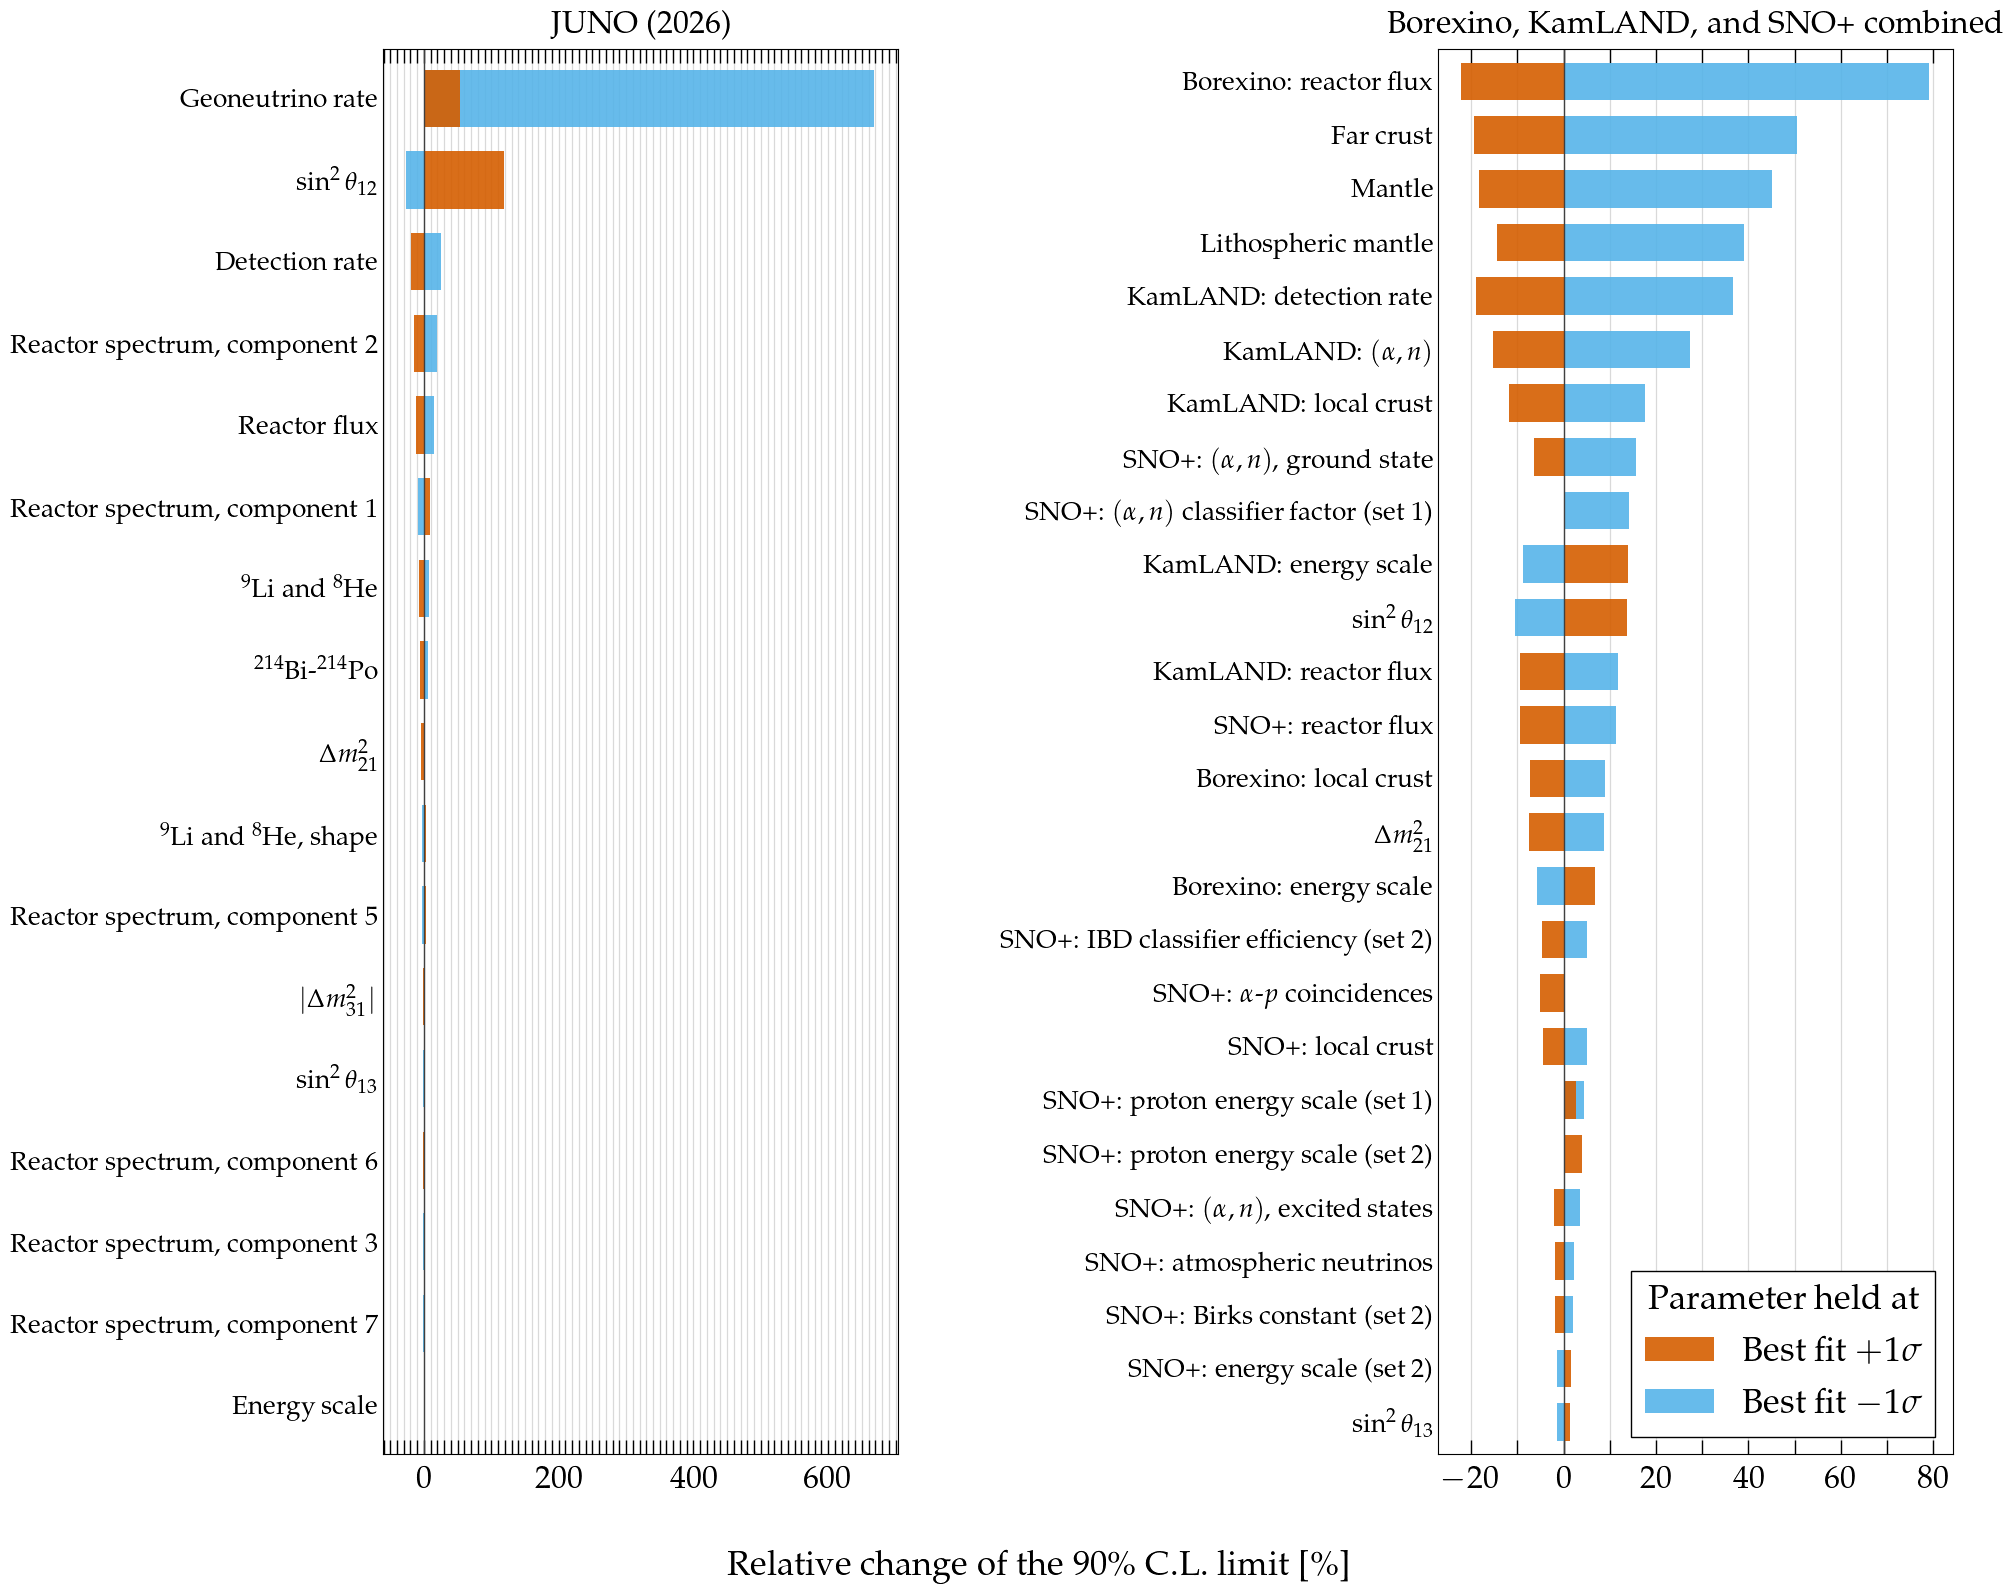

borexino: 6 shown, 8 left out; largest norm_reactor: +1 sigma -32%, -1 sigma +47%
kamland: 11 shown, 4 left out; largest delta_detector_rate: +1 sigma -18%, -1 sigma +43%
snoplus: 17 shown, 8 left out; largest class_a2[dataset1]: -1 sigma +71%
juno: 17 shown, 26 left out; largest norm_geo: +1 sigma +53%, -1 sigma +668%
combined_bx_kl_snoplus: 26 shown, 12 left out; largest norm_reactor@borexino: +1 sigma -22%, -1 sigma +79%


In [20]:
figdata = data.use("impacts_experiments")
fig = plot_impacts.figure_experiments()
save(fig, "impacts_experiments")
plt.show()

fig = plot_impacts.figure_juno_and_three()
save(fig, "impacts_juno_three")
plt.show()

for site in ("borexino", "kamland", "snoplus", "juno", "combined_bx_kl_snoplus"):
    rows, left_out = plot_impacts.shown(site)
    top = rows[0]
    print(f"{site}: {len(rows)} shown, {left_out} left out; largest {top[0]}: "
          + ", ".join(f"{side} sigma {100 * v:+.0f}%" for side, v in sorted(top[1].items())))

## Figure E.4

How the lifetime trades off against the parameters that move most with it, fit by fit.

Data: `data/corner_rows.json`.

wrote figures/corner_rows.pdf


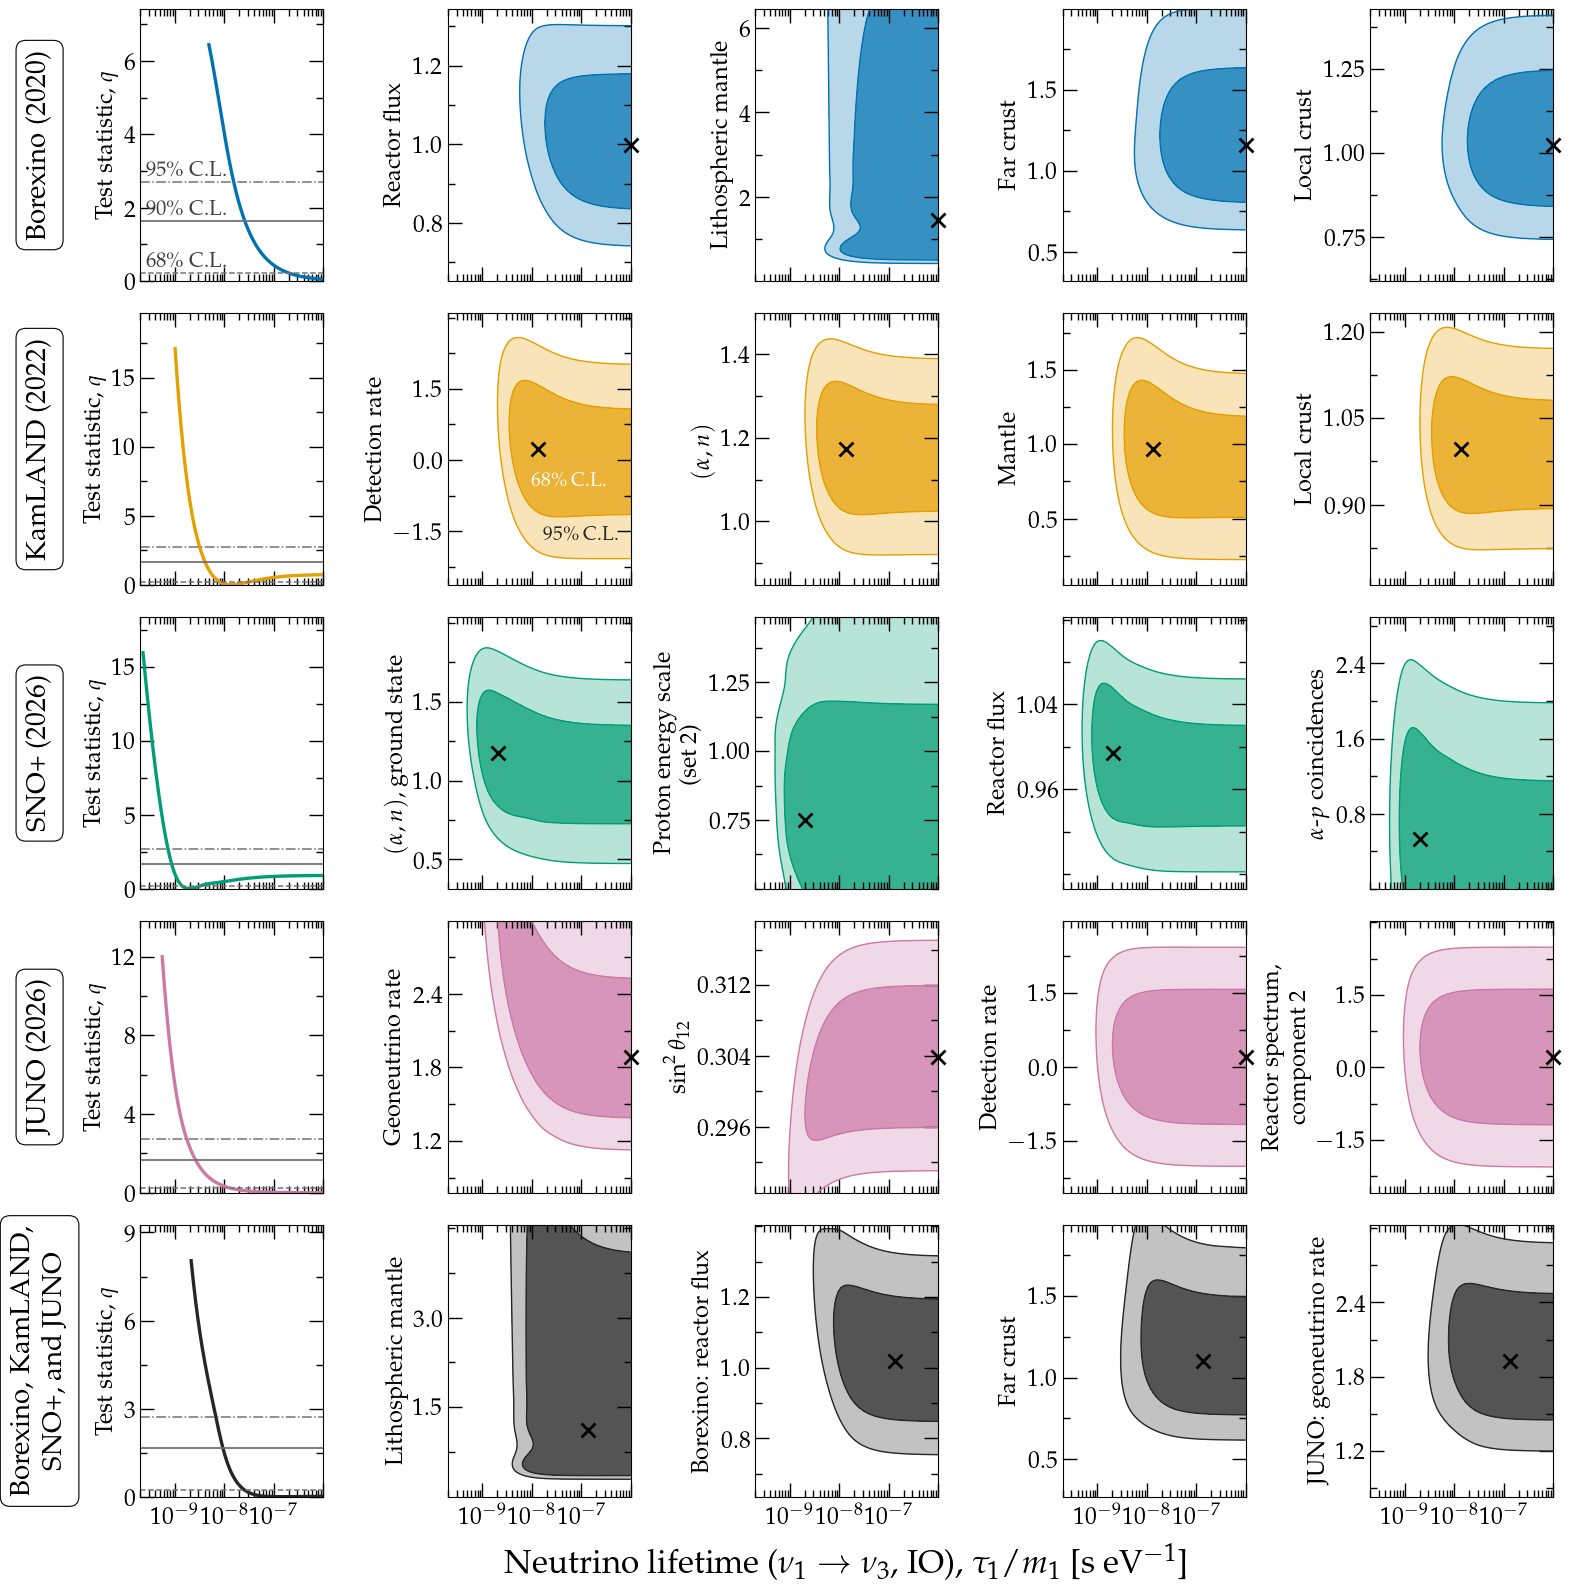

In [21]:
figdata = data.use("corner_rows")
from plotting import corners as plot_corners

fig = plot_corners.figure_rows()
save(fig, "corner_rows")
plt.show()

## Figure H.1

The constraint on the solar mixing parameters that our fits use.

Data: `data/nufit_constraints.json`.

wrote figures/nufit_constraints.pdf


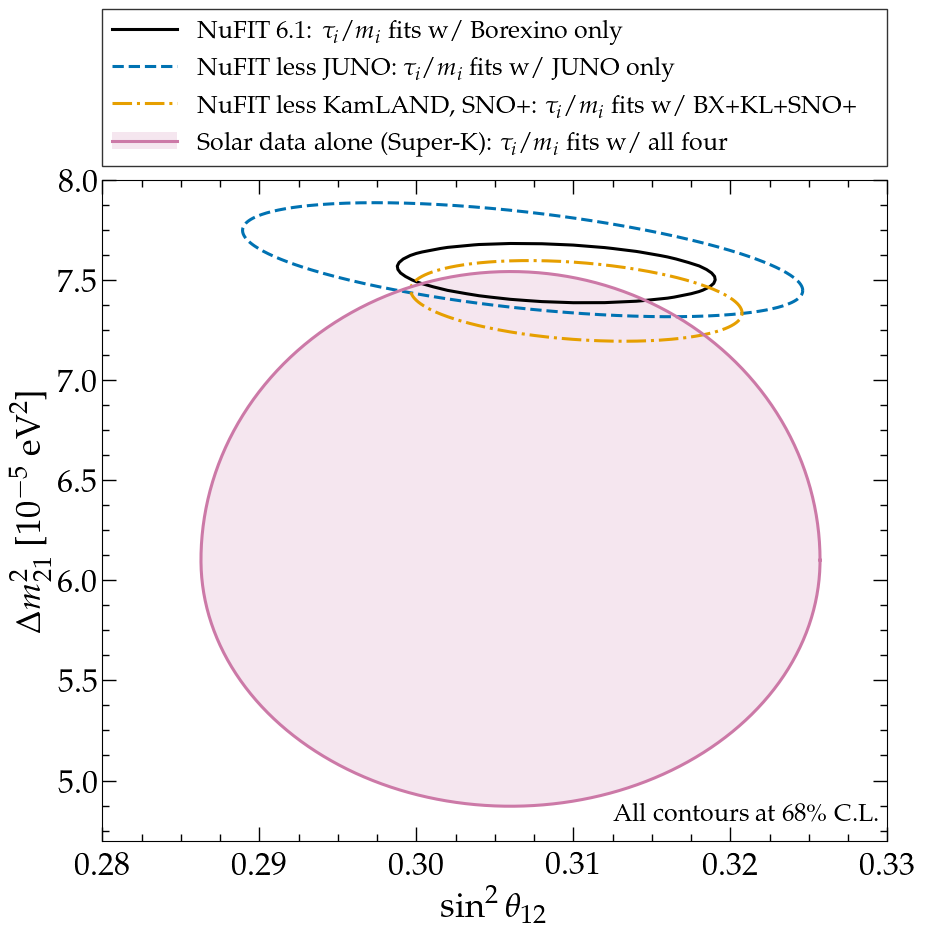

In [22]:
figdata = data.use("nufit_constraints")
from matplotlib.patches import Patch

con = figdata.nufit_constraints()
NUFIT_COLORS = {"nufit": "#000000", "juno": "#0072B2", "klsno": "#E69F00", "solar": "#CC79A7"}
fig, ax = plt.subplots(figsize=(10.0, 8.0))
x, y, chi = con["nufit"]
ax.contour(x, y, chi, levels=[con["level"]], colors=NUFIT_COLORS["nufit"], linewidths=2.2)
ax.plot(*con["less_juno"], color=NUFIT_COLORS["juno"], lw=2.2, ls="--")
ax.plot(*con["less_kamland_snoplus"], color=NUFIT_COLORS["klsno"], lw=2.2, ls="-.")
ax.fill(*con["solar_only"], color=NUFIT_COLORS["solar"], alpha=0.18, lw=0)
ax.plot(*con["solar_only"], color=NUFIT_COLORS["solar"], lw=2.2)
handles = [Line2D([], [], color=NUFIT_COLORS["nufit"], lw=2.2), Line2D([], [], color=NUFIT_COLORS["juno"], lw=2.2, ls="--"),
           Line2D([], [], color=NUFIT_COLORS["klsno"], lw=2.2, ls="-."),
           (Patch(facecolor=NUFIT_COLORS["solar"], alpha=0.18, lw=0), Line2D([], [], color=NUFIT_COLORS["solar"], lw=2.2))]
names = [r"NuFIT 6.1: $\tau_i/m_i$ fits w/ Borexino only", r"NuFIT less JUNO: $\tau_i/m_i$ fits w/ JUNO only",
         r"NuFIT less KamLAND, SNO+: $\tau_i/m_i$ fits w/ BX+KL+SNO+",
         r"Solar data alone (Super-K): $\tau_i/m_i$ fits w/ all four"]
# Above the panel, as in the money plot: beside the regions there is no room at the paper's ranges.
ax.legend(handles, names, loc="lower left", bbox_to_anchor=(0.0, 1.02, 1.0, 0.0), mode="expand", borderaxespad=0.0,
          ncol=1, frameon=True, edgecolor="k", fancybox=False, fontsize=18, handlelength=2.6)
ax.text(0.3295, 4.76, r"All contours at 68\% C.L.", color="k", fontsize=18, va="bottom", ha="right")
ax.set_xlim(0.28, 0.33)
ax.set_ylim(4.7, 8.0)
ax.set_xlabel(r"$\sin^2\theta_{12}$")
ax.set_ylabel(r"$\Delta m^2_{21}$ [$10^{-5}$~eV$^2$]")
minor_ticks(ax)
save(fig, "nufit_constraints")
plt.show()